<a href="https://colab.research.google.com/github/marbaniangsilan-droid/AloeCares/blob/main/AloeCare_Website_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ======================================
# AloeCare Website - Initial Setup
# ======================================

!pip install -q gradio ultralytics pillow

print("AloeCare setup completed successfully!")



AloeCare setup completed successfully!


In [ ]:

# Import required libraries

import gradio as gr
import sqlite3
import hashlib
import secrets
import os

from PIL import Image
from ultralytics import YOLO

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:

import os

CLASSIFY_PATH = "/content/drive/MyDrive/YOLO11/best.pt"

DETECT_PATH = "/content/drive/MyDrive/YOLO11/runs/aloe_vera_detection/weights/best.pt"

print("Classification Model:", os.path.exists(CLASSIFY_PATH))
print("Detection Model:", os.path.exists(DETECT_PATH))


Classification Model: True
Detection Model: True


In [ ]:

# Load trained Aloe vera models

from ultralytics import YOLO

# Load classification model
classify_model = YOLO(CLASSIFY_PATH)

# Load detection model
detect_model = YOLO(DETECT_PATH)

print("Classification model loaded successfully!")
print("Detection model loaded successfully!")

print("\nClassification classes:")
print(classify_model.names)

print("\nDetection classes:")
print(detect_model.names)


Classification model loaded successfully!
Detection model loaded successfully!

Classification classes:
{0: 'Aloe Rust', 1: 'Anthracnose', 2: 'Healthy', 3: 'Leaf Spot', 4: 'Sunburn'}

Detection classes:
{0: 'Aloe Rust', 1: 'Anthracnose', 2: 'Leaf Spot', 3: 'Sunburn'}


In [ ]:

import gradio as gr

custom_css = """
body {
    background: #f4f8f2;
}

.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#hero {
    background: linear-gradient(120deg, #e5f4df, #f7fbf4);
    border-radius: 20px;
    padding: 35px;
    text-align: center;
    border: 1px solid #d4e8ce;
}

#hero h1 {
    color: #245b36;
    font-size: 45px;
}

#hero p {
    color: #52745a;
    font-size: 17px;
}

.green-btn {
    background: #287a46 !important;
    color: white !important;
}
"""

with gr.Blocks(
    title="AloeCare",
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="lime"
    ),
    css=custom_css
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🌿 AloeCare</h1>
        <h2>AI-Powered Aloe Vera Disease Analysis</h2>
        <p>
        Welcome to AloeCare! Identify Aloe vera leaf diseases
        using Artificial Intelligence and YOLO11.
        </p>
    </div>
    """)

    gr.Markdown("## Welcome to AloeCare")

    gr.Markdown(
        "Register or log in to access our Aloe vera disease analysis system."
    )

    with gr.Row():
        with gr.Column():
            gr.Markdown("### 📝 Create Account")
            gr.Markdown("New users can register to access AloeCare.")

        with gr.Column():
            gr.Markdown("### 🔐 User Login")
            gr.Markdown("Existing users can log in to their accounts.")

    gr.Markdown("---")

    gr.Markdown(
        "### Our Services\n"
        "- 🌱 Disease Classification\n"
        "- 🔍 Disease Detection\n"
        "- 📊 AI Prediction Results"
    )

    gr.HTML("""
    <center>
    <p style="color:gray;">
    © 2026 AloeCare | Aloe Vera Disease Analysis System
    </p>
    </center>
    """)

demo.launch(share=True)


/tmp/ipykernel_13188/2900211798.py:37: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://289aef6c389363d0f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# =========================================================
# 🌿 AloeCare - Complete Interactive Website
# Welcome -> Register -> Login -> Dashboard
# Classification + Disease Detection
# =========================================================

import gradio as gr
import sqlite3
import hashlib
import secrets
import re
import os
from PIL import Image

# ---------------------------------------------------------
# 1. DATABASE SETUP
# ---------------------------------------------------------

DB_PATH = "/content/drive/MyDrive/YOLO11/aloecare_users.db"

def create_database():
    conn = sqlite3.connect(DB_PATH)
    conn.execute("""
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            full_name TEXT NOT NULL,
            email TEXT UNIQUE NOT NULL,
            password_hash TEXT NOT NULL,
            salt TEXT NOT NULL
        )
    """)
    conn.commit()
    conn.close()

create_database()


# ---------------------------------------------------------
# 2. PASSWORD SECURITY
# ---------------------------------------------------------

def hash_password(password, salt):
    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode(),
        bytes.fromhex(salt),
        200000
    ).hex()


# ---------------------------------------------------------
# 3. REGISTRATION
# ---------------------------------------------------------

def register_user(name, email, password, confirm):

    if not all([name, email, password, confirm]):
        return "Please fill in all fields.", gr.update(), gr.update()

    name = name.strip()
    email = email.strip().lower()

    if not name:
        return "Please enter your full name.", gr.update(), gr.update()

    if not re.fullmatch(r"[^@\s]+@[^@\s]+\.[^@\s]+", email):
        return "Please enter a valid email.", gr.update(), gr.update()

    if len(password) < 8:
        return "Password must contain at least 8 characters.", gr.update(), gr.update()

    if password != confirm:
        return "Passwords do not match.", gr.update(), gr.update()

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    try:
        conn = sqlite3.connect(DB_PATH)
        conn.execute("""
            INSERT INTO users
            (full_name, email, password_hash, salt)
            VALUES (?, ?, ?, ?)
        """, (name, email, password_hash, salt))

        conn.commit()
        conn.close()

        # Automatically navigate to Login
        return (
            "Registration successful! Please log in.",
            gr.update(visible=False),
            gr.update(visible=True, value=email)
        )

    except sqlite3.IntegrityError:
        return "This email is already registered. Please log in.", gr.update(), gr.update()


# ---------------------------------------------------------
# 4. LOGIN AUTHENTICATION
# ---------------------------------------------------------

def login_user(email, password):

    if not email or not password:
        return "Please enter your email and password.", None, gr.update(), gr.update()

    email = email.strip().lower()

    conn = sqlite3.connect(DB_PATH)
    cursor = conn.execute("""
        SELECT id, full_name, password_hash, salt
        FROM users WHERE email = ?
    """, (email,))

    user = cursor.fetchone()
    conn.close()

    if user is None:
        return "Account not found. Please register first.", None, gr.update(), gr.update()

    user_id, name, saved_hash, salt = user

    entered_hash = hash_password(password, salt)

    if not secrets.compare_digest(entered_hash, saved_hash):
        return "Incorrect password. Please try again.", None, gr.update(), gr.update()

    # Successful login
    session = {"id": user_id, "name": name}

    return (
        f"Welcome {name}!",
        session,
        gr.update(visible=False),
        gr.update(visible=True)
    )


# ---------------------------------------------------------
# 5. CLASSIFICATION
# ---------------------------------------------------------

def classify_leaf(image):

    if image is None:
        return "Please upload an Aloe vera image."

    results = classify_model.predict(
        source=image,
        imgsz=224,
        verbose=False
    )

    probs = results[0].probs

    disease = classify_model.names[int(probs.top1)]
    confidence = float(probs.top1conf) * 100

    return (
        f"Predicted Condition: {disease}\n"
        f"Confidence: {confidence:.2f}%"
    )


# ---------------------------------------------------------
# 6. DISEASE DETECTION
# ---------------------------------------------------------

def detect_leaf(image):

    if image is None:
        return None, "Please upload an Aloe vera image."

    results = detect_model.predict(
        source=image,
        conf=0.25,
        imgsz=960,
        verbose=False
    )

    annotated = results[0].plot()
    annotated = Image.fromarray(annotated[:, :, ::-1])

    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:
        return annotated, "No disease detected."

    report = []

    for box in boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item()) * 100

        disease = detect_model.names[class_id]

        report.append(
            f"{disease}: {confidence:.2f}%"
        )

    return annotated, "\n".join(report)


# ---------------------------------------------------------
# 7. WEBSITE DESIGN
# ---------------------------------------------------------

css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#hero {
    background: linear-gradient(120deg, #e2f2df, #f5faf1);
    padding: 35px;
    border-radius: 20px;
    text-align: center;
    border: 1px solid #cde4ca;
}

#hero h1 {
    color: #245b36;
    font-size: 45px;
}

#hero p {
    color: #52745a;
    font-size: 17px;
}

#main-title {
    color: #245b36;
    text-align: center;
}
"""


# ---------------------------------------------------------
# 8. BUILD COMPLETE WEBSITE
# ---------------------------------------------------------

with gr.Blocks(title="AloeCare") as demo:

    session = gr.State(None)

    # WELCOME PAGE
    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div id="hero">
            <h1>🌿 AloeCare</h1>
            <h2>AI-Powered Aloe Vera Disease Analysis</h2>
            <p>
            Welcome to AloeCare! Protect your Aloe vera plants
            with intelligent disease classification and detection.
            </p>
        </div>
        """)

        gr.Markdown("## Welcome to AloeCare")

        gr.Markdown(
            "Create your account to access our AI-powered "
            "Aloe vera disease analysis system."
        )

        welcome_register = gr.Button(
            "📝 Register Now",
            variant="primary",
            size="lg"
        )

    # REGISTRATION PAGE
    with gr.Column(visible=False) as registration_page:

        gr.Markdown("# 🌿 AloeCare - Create Account")

        reg_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        reg_email = gr.Textbox(
            label="Email Address",
            placeholder="Enter your email"
        )

        reg_password = gr.Textbox(
            label="Password",
            type="password"
        )

        reg_confirm = gr.Textbox(
            label="Confirm Password",
            type="password"
        )

        register_button = gr.Button(
            "Create Account",
            variant="primary"
        )

        reg_message = gr.Textbox(
            label="Registration Status",
            interactive=False
        )

        reg_back = gr.Button("Back to Welcome Page")

    # LOGIN PAGE
    with gr.Column(visible=False) as login_page:

        gr.Markdown("# 🔐 AloeCare - Login")

        login_email = gr.Textbox(
            label="Email Address"
        )

        login_password = gr.Textbox(
            label="Password",
            type="password"
        )

        login_button = gr.Button(
            "Login",
            variant="primary"
        )

        login_message = gr.Textbox(
            label="Login Status",
            interactive=False
        )

    # DASHBOARD
    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("# 🌿 AloeCare Dashboard")

        welcome_user = gr.Markdown("Welcome!")

        gr.Markdown(
            "Select a service to analyse your Aloe vera leaf."
        )

        with gr.Tabs():

            # CLASSIFICATION TAB
            with gr.Tab("🌱 Disease Classification"):

                gr.Markdown("### Aloe Vera Disease Classification")

                class_image = gr.Image(
                    type="pil",
                    label="Upload Aloe Vera Leaf"
                )

                class_button = gr.Button(
                    "Classify Disease",
                    variant="primary"
                )

                class_result = gr.Textbox(
                    label="Classification Result",
                    lines=3
                )

                class_button.click(
                    classify_leaf,
                    inputs=class_image,
                    outputs=class_result
                )

            # DETECTION TAB
            with gr.Tab("🔍 Disease Detection"):

                gr.Markdown("### Aloe Vera Disease Detection")

                detect_image_input = gr.Image(
                    type="pil",
                    label="Upload Aloe Vera Leaf"
                )

                detect_button = gr.Button(
                    "Detect Disease",
                    variant="primary"
                )

                detect_result_image = gr.Image(
                    label="Detection Result"
                )

                detect_result_text = gr.Textbox(
                    label="Detected Diseases",
                    lines=4
                )

                detect_button.click(
                    detect_leaf,
                    inputs=detect_image_input,
                    outputs=[
                        detect_result_image,
                        detect_result_text
                    ]
                )

        logout_button = gr.Button(
            "Logout",
            variant="stop"
        )

    # -----------------------------------------------------
    # NAVIGATION CONNECTIONS
    # -----------------------------------------------------

    def open_register():
        return (
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    def go_back():
        return (
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False)
        )

    welcome_register.click(
        open_register,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    reg_back.click(
        go_back,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    # Registration automatically opens Login
    register_button.click(
        register_user,
        inputs=[
            reg_name,
            reg_email,
            reg_password,
            reg_confirm
        ],
        outputs=[
            reg_message,
            registration_page,
            login_email
        ]
    ).then(
        lambda: (
            gr.update(visible=False),
            gr.update(visible=True)
        ),
        outputs=[
            welcome_page,
            login_page
        ]
    )

    # Login opens Dashboard
    def update_dashboard(user):
        return f"### Welcome, {user['name']}! 🌿"

    login_button.click(
        login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_message,
            session,
            login_page,
            dashboard_page
        ]
    ).then(
        update_dashboard,
        inputs=session,
        outputs=welcome_user
    )

    # Logout
    def logout():
        return (
            None,
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False),
            "",
            ""
        )

    logout_button.click(
        logout,
        outputs=[
            session,
            welcome_page,
            registration_page,
            dashboard_page,
            login_password,
            login_message
        ]
    )


# ---------------------------------------------------------
# 9. LAUNCH WEBSITE
# ---------------------------------------------------------

demo.launch(
    share=True,
    theme=gr.themes.Soft(primary_hue="green"),
    css=css
)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://20f4322cc83be5a57b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ==========================================
# ALOECARE - CODE 1: WELCOME PAGE
# ==========================================

import gradio as gr

# Website design
css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#hero {
    background: linear-gradient(120deg, #e2f2df, #f5faf1);
    padding: 40px;
    border-radius: 20px;
    text-align: center;
    border: 1px solid #cde4ca;
}

#hero h1 {
    color: #245b36;
    font-size: 45px;
}

#hero p {
    color: #52745a;
    font-size: 17px;
}
"""

# Create website
with gr.Blocks(
    title="AloeCare",
    theme=gr.themes.Soft(primary_hue="green"),
    css=css
) as demo:

    # Welcome Page
    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div id="hero">
            <h1>🌿 AloeCare</h1>
            <h2>AI-Powered Aloe Vera Disease Analysis</h2>
            <p>
                Welcome to AloeCare! Protect your Aloe vera plants
                with intelligent disease classification and detection.
            </p>
        </div>
        """)

        gr.Markdown("## Welcome to AloeCare")

        gr.Markdown(
            "Create your account to access our AI-powered "
            "Aloe vera disease analysis system."
        )

        welcome_register = gr.Button(
            "📝 Register Now",
            variant="primary",
            size="lg"
        )

    # Registration page placeholder
    with gr.Column(visible=False) as registration_page:
        gr.Markdown("# AloeCare Registration Page")

    # Button navigation
    welcome_register.click(
        lambda: (
            gr.update(visible=False),
            gr.update(visible=True)
        ),
        outputs=[
            welcome_page,
            registration_page
        ]
    )

# Launch
demo.launch(share=True)


/tmp/ipykernel_13188/2969966320.py:34: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b035f49716704bdecb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ============================================================
#                 ALOECARE WEBSITE
# ============================================================

import os
import re
import sqlite3
import hashlib
import secrets

import gradio as gr
import numpy as np

from PIL import Image
from ultralytics import YOLO
from google.colab import drive

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# ============================================================
# 2. LOAD CLASSIFICATION AND DETECTION MODELS
# ============================================================

CLASSIFY_PATH = "/content/drive/MyDrive/YOLO11/best.pt"

DETECT_PATH = (
    "/content/drive/MyDrive/YOLO11/"
    "runs/aloe_vera_detection/weights/best.pt"
)

if not os.path.exists(CLASSIFY_PATH):
    raise FileNotFoundError("Classification model not found: " + CLASSIFY_PATH)

if not os.path.exists(DETECT_PATH):
    raise FileNotFoundError("Detection model not found: " + DETECT_PATH)

classify_model = YOLO(CLASSIFY_PATH)
detect_model = YOLO(DETECT_PATH)

print("Classification model loaded successfully!")
print("Detection model loaded successfully!")

# ============================================================
# 3. DATABASE SETUP
# ============================================================

DB_PATH = "/content/drive/MyDrive/YOLO11/aloecare_users.db"

def connect_db():
    conn = sqlite3.connect(DB_PATH, timeout=30)
    conn.execute("PRAGMA busy_timeout = 30000")
    return conn

def create_database():
    conn = connect_db()
    try:
        cursor = conn.cursor()

        cursor.execute("""
            CREATE TABLE IF NOT EXISTS users (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                full_name TEXT NOT NULL,
                email TEXT UNIQUE NOT NULL,
                password_hash TEXT NOT NULL,
                salt TEXT NOT NULL
            )
        """)

        conn.commit()
    finally:
        conn.close()

create_database()

print("Database ready!")

# ============================================================
# 4. PASSWORD HASHING
# ============================================================

def hash_password(password, salt):
    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode("utf-8"),
        salt.encode("utf-8"),
        200000
    ).hex()

# ============================================================
# 5. REGISTRATION FUNCTION
# ============================================================

def register_user(name, email, password, confirm_password):

    name = (name or "").strip()
    email = (email or "").strip().lower()

    if not name or not email or not password or not confirm_password:
        return (
            "Please fill in all fields.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if not re.fullmatch(r"[^@\s]+@[^@\s]+\.[^@\s]+", email):
        return (
            "Please enter a valid email address.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if len(password) < 8:
        return (
            "Password must contain at least 8 characters.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if password != confirm_password:
        return (
            "Passwords do not match.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    conn = None

    try:
        conn = connect_db()
        cursor = conn.cursor()

        cursor.execute("BEGIN IMMEDIATE")

        cursor.execute("""
            INSERT INTO users
            (full_name, email, password_hash, salt)
            VALUES (?, ?, ?, ?)
        """, (name, email, password_hash, salt))

        conn.commit()

        return (
            "Registration successful! Please log in.",
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except sqlite3.IntegrityError:
        if conn:
            conn.rollback()

        return (
            "This email is already registered. Please log in.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    except Exception as e:
        if conn:
            conn.rollback()

        return (
            f"Registration error: {str(e)}",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    finally:
        if conn:
            conn.close()

# ============================================================
# 6. LOGIN FUNCTION
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:
        return (
            "Please enter your email and password.",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    conn = None

    try:
        conn = connect_db()
        cursor = conn.cursor()

        cursor.execute("""
            SELECT full_name, password_hash, salt
            FROM users
            WHERE email = ?
        """, (email,))

        user = cursor.fetchone()

        if user is None:
            return (
                "Account not found. Please register first.",
                gr.update(visible=True),
                gr.update(visible=False),
                None
            )

        full_name, stored_hash, salt = user
        entered_hash = hash_password(password, salt)

        if secrets.compare_digest(entered_hash, stored_hash):
            return (
                f"Welcome, {full_name}!",
                gr.update(visible=False),
                gr.update(visible=True),
                email
            )

        return (
            "Incorrect password. Please try again.",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    except Exception as e:
        return (
            f"Login error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    finally:
        if conn:
            conn.close()

# ============================================================
# 7. CLASSIFICATION FUNCTION
# ============================================================

def classify_leaf(image):

    if image is None:
        return "Please upload an Aloe vera leaf image.", ""

    try:
        results = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )

        probs = results[0].probs
        scores = probs.data.cpu().numpy()
        names = classify_model.names

        top_index = int(probs.top1)
        disease = names[top_index]
        confidence = float(probs.top1conf) * 100

        report = f"""
# AloeCare Classification Result

## Predicted Condition: {disease}

**Confidence: {confidence:.2f}%**

---

### Disease Probability Scores

"""

        for class_id, score in enumerate(scores):

            disease_name = names[class_id]
            percentage = float(score) * 100

            bar_count = min(20, round(percentage / 5))
            bar = "🟩" * bar_count + "⬜" * (20 - bar_count)

            report += (
                f"**{disease_name}: {percentage:.2f}%**\n\n"
                f"{bar}\n\n"
            )

        return report, "Classification completed successfully!"

    except Exception as e:
        return f"Classification error: {str(e)}", "Please try again."

# ============================================================
# 8. DETECTION FUNCTION
# ============================================================

def detect_leaf(image):

    if image is None:
        return None, "Please upload an Aloe vera leaf image."

    try:
        results = detect_model.predict(
            source=image,
            conf=0.25,
            imgsz=960,
            verbose=False
        )

        annotated = results[0].plot()
        annotated = Image.fromarray(annotated[:, :, ::-1])

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            return annotated, "No disease detected."

        report = "# AloeCare Disease Detection Results\n\n"

        for box in boxes:

            class_id = int(box.cls.item())
            confidence = float(box.conf.item()) * 100
            disease = detect_model.names[class_id]

            report += f"**{disease}: {confidence:.2f}%**\n\n"

        return annotated, report

    except Exception as e:
        return None, f"Detection error: {str(e)}"

# ============================================================
# 9. PAGE NAVIGATION FUNCTIONS
# ============================================================

def open_registration():
    return (
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False)
    )

def open_login():
    return (
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=True)
    )

def back_to_welcome():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False)
    )

def logout():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        None
    )

# ============================================================
# 10. WEBSITE DESIGN
# ============================================================

custom_css = """
.welcome-box {
    background-color: #b7e4c7;
    color: #111111;
    padding: 35px 20px;
    border-radius: 14px;
    text-align: center;
    border: 2px solid #74c69d;
    margin-bottom: 20px;
}
.welcome-box h1 {
    color: #111111 !important;
    font-size: 34px;
    font-weight: bold;
}
"""

# ============================================================
# 11. CREATE WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    css=custom_css
) as demo:

    session_user = gr.State(value=None)

    # --------------------------------------------------------
    # WELCOME PAGE
    # --------------------------------------------------------

    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div class="welcome-box">
            <h1>Welcome to AloeCare</h1>
        </div>
        """)

        register_open = gr.Button(
            "Register",
            variant="primary"
        )

        login_open = gr.Button(
            "Login"
        )

    # --------------------------------------------------------
    # REGISTRATION PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as registration_page:

        gr.Markdown("# Create Your Account")

        reg_name = gr.Textbox(label="Full Name")
        reg_email = gr.Textbox(label="Email Address")

        reg_password = gr.Textbox(
            label="Password",
            type="password"
        )

        reg_show_password = gr.Checkbox(
            label="👁 Show password"
        )

        reg_confirm_password = gr.Textbox(
            label="Confirm Password",
            type="password"
        )

        reg_show_confirm = gr.Checkbox(
            label="👁 Show confirm password"
        )

        register_button = gr.Button(
            "Create Account",
            variant="primary"
        )

        register_status = gr.Markdown()

        registration_back = gr.Button("Back to Welcome")

    # --------------------------------------------------------
    # LOGIN PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as login_page:

        gr.Markdown("# AloeCare Login")

        login_email = gr.Textbox(
            label="Email Address"
        )

        login_password = gr.Textbox(
            label="Password",
            type="password"
        )

        login_show_password = gr.Checkbox(
            label="👁 Show password"
        )

        login_button = gr.Button(
            "Login",
            variant="primary"
        )

        login_status = gr.Markdown()

        login_back = gr.Button("Back to Welcome")

    # --------------------------------------------------------
    # DASHBOARD PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("""
        # AloeCare Dashboard

        Aloe Vera Disease Classification and Detection
        """)

        with gr.Tabs():

            # CLASSIFICATION TAB

            with gr.Tab("Disease Classification"):

                gr.Markdown("### Upload Aloe Vera Leaf Image")

                class_image = gr.Image(
                    type="pil",
                    label="Upload Leaf Image"
                )

                class_button = gr.Button(
                    "Classify Disease",
                    variant="primary"
                )

                class_result = gr.Markdown()

                class_status = gr.Textbox(
                    label="Analysis Status",
                    interactive=False
                )

                class_button.click(
                    classify_leaf,
                    inputs=class_image,
                    outputs=[class_result, class_status]
                )

            # DETECTION TAB

            with gr.Tab("Disease Detection"):

                gr.Markdown("### Detect Diseases with Bounding Boxes")

                detect_image_input = gr.Image(
                    type="pil",
                    label="Upload Leaf Image"
                )

                detect_button = gr.Button(
                    "Detect Disease",
                    variant="primary"
                )

                detect_result_image = gr.Image(
                    label="Detection Result"
                )

                detect_result_text = gr.Markdown()

                detect_button.click(
                    detect_leaf,
                    inputs=detect_image_input,
                    outputs=[
                        detect_result_image,
                        detect_result_text
                    ]
                )

        logout_button = gr.Button(
            "Logout",
            variant="stop"
        )

    # ========================================================
    # 12. CONNECT BUTTONS
    # ========================================================

    register_open.click(
        open_registration,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    login_open.click(
        open_login,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    register_button.click(
        register_user,
        inputs=[
            reg_name,
            reg_email,
            reg_password,
            reg_confirm_password
        ],
        outputs=[
            register_status,
            welcome_page,
            registration_page,
            login_page
        ]
    )

    registration_back.click(
        back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    login_button.click(
        login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_status,
            login_page,
            dashboard_page,
            session_user
        ]
    )

    login_back.click(
        back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    logout_button.click(
        logout,
        outputs=[
            welcome_page,
            dashboard_page,
            session_user
        ]
    )

    # ========================================================
    # 13. PASSWORD SHOW / HIDE
    # ========================================================

    reg_show_password.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=reg_show_password,
        outputs=reg_password
    )

    reg_show_confirm.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=reg_show_confirm,
        outputs=reg_confirm_password
    )

    login_show_password.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=login_show_password,
        outputs=login_password
    )

# ============================================================
# 14. LAUNCH WEBSITE
# ============================================================

demo.launch(share=True)


Classification model loaded successfully!
Detection model loaded successfully!
Database ready!


/tmp/ipykernel_13188/1243660494.py:407: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7068d4206f1e90d3a1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install ultralytics

In [ ]:
from PIL import Image
from ultralytics import YOLO
from google.colab import drive

In [ ]:

# ============================================================
#                 ALOECARE WEBSITE
# ============================================================

import os
import re
import sqlite3
import hashlib
import secrets

import gradio as gr
import numpy as np

from PIL import Image
from ultralytics import YOLO
from google.colab import drive


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")


# ============================================================
# 2. LOAD CLASSIFICATION AND DETECTION MODELS
# ============================================================

CLASSIFY_PATH = "/content/drive/MyDrive/YOLO11/best.pt"

DETECT_PATH = (
    "/content/drive/MyDrive/YOLO11/"
    "runs/aloe_vera_detection/weights/best.pt"
)

if not os.path.exists(CLASSIFY_PATH):
    raise FileNotFoundError(
        "Classification model not found: " + CLASSIFY_PATH
    )

if not os.path.exists(DETECT_PATH):
    raise FileNotFoundError(
        "Detection model not found: " + DETECT_PATH
    )

classify_model = YOLO(CLASSIFY_PATH)
detect_model = YOLO(DETECT_PATH)

print("Classification model loaded successfully!")
print("Detection model loaded successfully!")


# ============================================================
# 3. DATABASE SETUP
# ============================================================

DB_PATH = "/content/drive/MyDrive/YOLO11/aloecare_users.db"


def connect_db():
    conn = sqlite3.connect(DB_PATH, timeout=30)
    conn.execute("PRAGMA busy_timeout = 30000")
    return conn


def create_database():

    conn = connect_db()

    try:

        cursor = conn.cursor()

        cursor.execute("""
            CREATE TABLE IF NOT EXISTS users (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                full_name TEXT NOT NULL,
                email TEXT UNIQUE NOT NULL,
                password_hash TEXT NOT NULL,
                salt TEXT NOT NULL
            )
        """)

        conn.commit()

    finally:
        conn.close()


create_database()

print("Database ready!")


# ============================================================
# 4. PASSWORD HASHING
# ============================================================

def hash_password(password, salt):

    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode("utf-8"),
        salt.encode("utf-8"),
        200000
    ).hex()


# ============================================================
# 5. REGISTRATION FUNCTION
# ============================================================

def register_user(name, email, password, confirm_password):

    name = (name or "").strip()
    email = (email or "").strip().lower()

    if not name or not email or not password or not confirm_password:

        return (
            "Please fill in all fields.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if not re.fullmatch(r"[^@\s]+@[^@\s]+\.[^@\s]+", email):

        return (
            "Please enter a valid email address.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if len(password) < 8:

        return (
            "Password must contain at least 8 characters.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if password != confirm_password:

        return (
            "Passwords do not match.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    conn = None

    try:

        conn = connect_db()
        cursor = conn.cursor()

        cursor.execute("BEGIN IMMEDIATE")

        cursor.execute("""
            INSERT INTO users
            (full_name, email, password_hash, salt)
            VALUES (?, ?, ?, ?)
        """, (name, email, password_hash, salt))

        conn.commit()

        return (
            "Registration successful! Please log in.",
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except sqlite3.IntegrityError:

        if conn:
            conn.rollback()

        return (
            "This email is already registered. Please log in.",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    except Exception as e:

        if conn:
            conn.rollback()

        return (
            f"Registration error: {str(e)}",
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )

    finally:

        if conn:
            conn.close()


# ============================================================
# 6. LOGIN FUNCTION
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:

        return (
            "Please enter your email and password.",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    conn = None

    try:

        conn = connect_db()
        cursor = conn.cursor()

        cursor.execute("""
            SELECT full_name, password_hash, salt
            FROM users
            WHERE email = ?
        """, (email,))

        user = cursor.fetchone()

        if user is None:

            return (
                "Account not found. Please register first.",
                gr.update(visible=True),
                gr.update(visible=False),
                None
            )

        full_name, stored_hash, salt = user

        entered_hash = hash_password(password, salt)

        if secrets.compare_digest(entered_hash, stored_hash):

            return (
                f"Welcome, {full_name}!",
                gr.update(visible=False),
                gr.update(visible=True),
                email
            )

        return (
            "Incorrect password. Please try again.",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    except Exception as e:

        return (
            f"Login error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False),
            None
        )

    finally:

        if conn:
            conn.close()


# ============================================================
# 7. CLASSIFICATION FUNCTION
# ============================================================

def classify_leaf(image):

    if image is None:
        return "Please upload an Aloe vera leaf image.", ""

    try:

        results = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )

        probs = results[0].probs
        scores = probs.data.cpu().numpy()
        names = classify_model.names

        top_index = int(probs.top1)
        disease = names[top_index]
        confidence = float(probs.top1conf) * 100

        report = f"""
# AloeCare Classification Result

## Predicted Condition: {disease}

**Confidence: {confidence:.2f}%**

---

### Disease Probability Scores

"""

        for class_id, score in enumerate(scores):

            disease_name = names[class_id]
            percentage = float(score) * 100

            bar_count = min(20, round(percentage / 5))

            bar = "🟩" * bar_count + "⬜" * (20 - bar_count)

            report += (
                f"**{disease_name}: {percentage:.2f}%**\n\n"
                f"{bar}\n\n"
            )

        return report, "Classification completed successfully!"

    except Exception as e:

        return (
            f"Classification error: {str(e)}",
            "Please try again."
        )


# ============================================================
# 8. DETECTION FUNCTION
# ============================================================

def detect_leaf(image):

    if image is None:
        return None, "Please upload an Aloe vera leaf image."

    try:

        results = detect_model.predict(
            source=image,
            conf=0.25,
            imgsz=960,
            verbose=False
        )

        annotated = results[0].plot()

        annotated = Image.fromarray(
            annotated[:, :, ::-1]
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:

            return annotated, "No disease detected."

        report = "# AloeCare Disease Detection Results\n\n"

        for box in boxes:

            class_id = int(box.cls.item())

            confidence = float(box.conf.item()) * 100

            disease = detect_model.names[class_id]

            report += (
                f"**{disease}: {confidence:.2f}%**\n\n"
            )

        return annotated, report

    except Exception as e:

        return None, f"Detection error: {str(e)}"


# ============================================================
# 9. PAGE NAVIGATION FUNCTIONS
# ============================================================

def open_registration():

    return (
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False)
    )


def open_login():

    return (
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=True)
    )


def back_to_welcome():

    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False)
    )


def logout():

    return (
        gr.update(visible=True),
        gr.update(visible=False),
        None
    )


# ============================================================
# 10. WEBSITE DESIGN - CSS
# ============================================================

custom_css = """

.gradio-container {
    max-width: 1050px !important;
    margin: auto !important;
}

/* WELCOME PAGE CARD */

.welcome-box {
    max-width: 520px;
    margin: 20px auto;
    background: white;
    border-radius: 20px;
    overflow: hidden;
    text-align: center;
    box-shadow: 0 5px 20px rgba(0,0,0,0.10);
    border: 1px solid #e5eee7;
}

/* ALOE VERA IMAGE */

.welcome-leaf {
    height: 250px;
    overflow: hidden;
    background: #174d32;
    border-radius: 0 0 45% 10%;
}

.welcome-leaf img {
    width: 100%;
    height: 100%;
    object-fit: cover;
    object-position: center 45%;
}

/* WELCOME TEXT */

.welcome-content {
    padding: 28px 20px 25px;
    background: white;
}

.welcome-content h1 {
    color: #174d32 !important;
    font-size: 32px;
    font-weight: bold;
    margin: 0;
}

/* REGISTER AND LOGIN BUTTONS */

.welcome-action {
    max-width: 520px !important;
    margin: 10px auto !important;
}

.welcome-action button {
    background: #145c39 !important;
    color: white !important;
    border-radius: 12px !important;
    height: 250px !important;
    min-height: 250px !important;
    font-size: 20px !important;
    font-weight: 600 !important;
    border: none !important;
    width: 100% !important;
}

.welcome-action button:hover {
    background: #247b4d !important;
}

/* REGISTRATION AND LOGIN BOXES */

.auth-card {
    max-width: 460px !important;
    margin: 20px auto !important;
    padding: 22px !important;
    border: 1px solid #d5e8d9;
    border-radius: 14px;
}

.auth-card input {
    min-height: 38px !important;
}

"""


# ============================================================
# 11. CREATE WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    css=custom_css,
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald"
    )
) as demo:

    session_user = gr.State(value=None)


    # ========================================================
    # WELCOME PAGE - UPDATED DESIGN ONLY
    # ========================================================

    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div class="welcome-box">

            <div class="welcome-leaf">

                <img
                    src="https://commons.wikimedia.org/wiki/Special:FilePath/Aloe_Vera_growing_plant.jpg"
                    alt="Aloe Vera Plant"
                >

            </div>

            <div class="welcome-content">

                <h1>Welcome to AloeCare</h1>

            </div>

        </div>
        """)

        register_open = gr.Button(
            "Register",
            variant="primary",
            elem_classes=["welcome-action"]
        )

        login_open = gr.Button(
            "Login",
            elem_classes=["welcome-action"]
        )


    # ========================================================
    # REGISTRATION PAGE
    # ========================================================

    with gr.Column(
        visible=False,
        elem_classes=["auth-card"]
    ) as registration_page:

        gr.Markdown("# Create Your Account")

        reg_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        reg_email = gr.Textbox(
            label="Email Address",
            placeholder="Enter your email"
        )

        reg_password = gr.Textbox(
            label="Password",
            type="password",
            placeholder="Enter password"
        )

        reg_show_password = gr.Checkbox(
            label="👁 Show password"
        )

        reg_confirm_password = gr.Textbox(
            label="Confirm Password",
            type="password",
            placeholder="Confirm password"
        )

        reg_show_confirm = gr.Checkbox(
            label="👁 Show confirm password"
        )

        register_button = gr.Button(
            "Create Account",
            variant="primary"
        )

        register_status = gr.Markdown()

        registration_back = gr.Button("Back to Welcome")


    # ========================================================
    # LOGIN PAGE
    # ========================================================

    with gr.Column(
        visible=False,
        elem_classes=["auth-card"]
    ) as login_page:

        gr.Markdown("# AloeCare Login")

        login_email = gr.Textbox(
            label="Email Address",
            placeholder="Enter your email"
        )

        login_password = gr.Textbox(
            label="Password",
            type="password",
            placeholder="Enter your password"
        )

        login_show_password = gr.Checkbox(
            label="👁 Show password"
        )

        login_button = gr.Button(
            "Login",
            variant="primary"
        )

        login_status = gr.Markdown()

        login_back = gr.Button("Back to Welcome")


    # ========================================================
    # DASHBOARD PAGE
    # ========================================================

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("""
        # AloeCare Dashboard

        Aloe Vera Disease Classification and Detection
        """)

        with gr.Tabs():

            # CLASSIFICATION TAB

            with gr.Tab("Disease Classification"):

                gr.Markdown("### Upload Aloe Vera Leaf Image")

                class_image = gr.Image(
                    type="pil",
                    label="Upload Leaf Image"
                )

                class_button = gr.Button(
                    "Classify Disease",
                    variant="primary"
                )

                class_result = gr.Markdown()

                class_status = gr.Textbox(
                    label="Analysis Status",
                    interactive=False
                )

                class_button.click(
                    classify_leaf,
                    inputs=class_image,
                    outputs=[
                        class_result,
                        class_status
                    ]
                )


            # DETECTION TAB

            with gr.Tab("Disease Detection"):

                gr.Markdown(
                    "### Detect Diseases with Bounding Boxes"
                )

                detect_image_input = gr.Image(
                    type="pil",
                    label="Upload Leaf Image"
                )

                detect_button = gr.Button(
                    "Detect Disease",
                    variant="primary"
                )

                detect_result_image = gr.Image(
                    label="Detection Result"
                )

                detect_result_text = gr.Markdown()

                detect_button.click(
                    detect_leaf,
                    inputs=detect_image_input,
                    outputs=[
                        detect_result_image,
                        detect_result_text
                    ]
                )


        logout_button = gr.Button(
            "Logout",
            variant="stop"
        )


    # ========================================================
    # 12. CONNECT BUTTONS
    # ========================================================

    register_open.click(
        open_registration,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    login_open.click(
        open_login,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    register_button.click(
        register_user,
        inputs=[
            reg_name,
            reg_email,
            reg_password,
            reg_confirm_password
        ],
        outputs=[
            register_status,
            welcome_page,
            registration_page,
            login_page
        ]
    )

    registration_back.click(
        back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    login_button.click(
        login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_status,
            login_page,
            dashboard_page,
            session_user
        ]
    )

    login_back.click(
        back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page
        ]
    )

    logout_button.click(
        logout,
        outputs=[
            welcome_page,
            dashboard_page,
            session_user
        ]
    )


    # ========================================================
    # 13. PASSWORD SHOW / HIDE
    # ========================================================

    reg_show_password.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=reg_show_password,
        outputs=reg_password
    )

    reg_show_confirm.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=reg_show_confirm,
        outputs=reg_confirm_password
    )

    login_show_password.change(
        lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=login_show_password,
        outputs=login_password
    )


# ============================================================
# 14. LAUNCH WEBSITE
# ============================================================

demo.launch(share=True)


Classification model loaded successfully!
Detection model loaded successfully!
Database ready!


/tmp/ipykernel_13188/3216964968.py:540: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7cd1a7ab6f19fb1788.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics gradio

In [ ]:




from google.colab import files

uploaded = files.upload()





In [ ]:



from google.colab import files

uploaded = files.upload()

print("\nUploaded filenames:")
print(list(uploaded.keys()))




In [ ]:

import zipfile
import os

zip_path = "/content/classify_best.pt.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/classify_model")

print("ZIP file extracted successfully!")

for root, dirs, files_list in os.walk("/content/classify_model"):
    for file in files_list:
        print(os.path.join(root, file))


In [ ]:

import zipfile
import os
import shutil

source = "/content/classify_best.pt.zip"
destination = "/content/classify_best.pt"

with zipfile.ZipFile(source, "r") as z:
    # Recreate the original PyTorch archive structure
    z.extractall("/content/rebuild_classify")

# Locate the extracted best folder
model_folder = "/content/rebuild_classify/best"

# Rebuild it as a PyTorch ZIP checkpoint
shutil.make_archive(
    "/content/classify_best",
    "zip",
    root_dir="/content/rebuild_classify",
    base_dir="best"
)

os.rename("/content/classify_best.zip", destination)

print("Model file created:", os.path.exists(destination))
print("File size:", os.path.getsize(destination), "bytes")


In [ ]:

!pip install -q ultralytics

from ultralytics import YOLO

classify_model = YOLO("/content/classify_best.pt")

print("Task:", classify_model.task)
print("Classes:", classify_model.names)


In [ ]:

from google.colab import files

uploaded_detect = files.upload()

print("Uploaded file:", list(uploaded_detect.keys()))


In [ ]:

import zipfile
import os

detect_zip = "/content/" + list(uploaded_detect.keys())[0]

with zipfile.ZipFile(detect_zip, "r") as zip_ref:
    zip_ref.extractall("/content/detect_model")

print("Detection ZIP extracted successfully!")

for root, dirs, files_list in os.walk("/content/detect_model"):
    for file in files_list:
        if file == "best.pt":
            print("Found model:", os.path.join(root, file))


In [ ]:

import os

print("Searching for detection model files...\n")

for root, dirs, files_list in os.walk("/content/detect_model"):
    for file in files_list:
        if file == "best.pt" or file.endswith(".zip"):
            print(os.path.join(root, file))


In [ ]:

import os

for root, dirs, files_list in os.walk("/content/detect_model"):
    for file in files_list[:10]:
        print(os.path.join(root, file))


In [ ]:

import os
import shutil

source_folder = "/content/detect_model"

# Rebuild the PyTorch checkpoint archive
shutil.make_archive(
    "/content/detect_best",
    "zip",
    root_dir=source_folder,
    base_dir="best"
)

# Rename the archive to .pt
os.rename(
    "/content/detect_best.zip",
    "/content/detect_best.pt"
)

print("Detection model created!")
print("File exists:", os.path.exists("/content/detect_best.pt"))
print("File size:", os.path.getsize("/content/detect_best.pt"), "bytes")


In [ ]:

from ultralytics import YOLO

detect_model = YOLO("/content/detect_best.pt")

print("Detection task:", detect_model.task)
print("Detection classes:", detect_model.names)


In [ ]:

print("Classification model:", classify_model.task)
print("Classification classes:", classify_model.names)

print("\nDetection model:", detect_model.task)
print("Detection classes:", detect_model.names)


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

model_folder = "/content/drive/MyDrive/AloeCare_Models"
os.makedirs(model_folder, exist_ok=True)

shutil.copy2(
    "/content/classify_best.pt",
    model_folder + "/classify_best.pt"
)

shutil.copy2(
    "/content/detect_best.pt",
    model_folder + "/detect_best.pt"
)

print("Both models saved successfully!")

print(os.listdir(model_folder))


In [ ]:

# ============================================================
#                       ALOECARE WEBSITE
#       Aloe Vera Disease Classification and Detection
# ============================================================

import os
import re
import sqlite3
import hashlib
import secrets

import gradio as gr
import numpy as np

from PIL import Image
from ultralytics import YOLO


# ============================================================
# 1. LOAD THE TWO TRAINED MODELS
# ============================================================

CLASSIFY_PATH = "/content/classify_best.pt"
DETECT_PATH = "/content/detect_best.pt"

if not os.path.exists(CLASSIFY_PATH):
    raise FileNotFoundError("Classification model not found!")

if not os.path.exists(DETECT_PATH):
    raise FileNotFoundError("Detection model not found!")

print("Loading classification model...")
classify_model = YOLO(CLASSIFY_PATH)

print("Loading detection model...")
detect_model = YOLO(DETECT_PATH)

print("Both models loaded successfully!")

print("Classification classes:", classify_model.names)
print("Detection classes:", detect_model.names)


# ============================================================
# 2. DATABASE
# ============================================================

DB_PATH = "/content/aloecare_users.db"

def create_database():
    conn = sqlite3.connect(DB_PATH, timeout=30)

    conn.execute("""
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            full_name TEXT NOT NULL,
            email TEXT UNIQUE NOT NULL,
            password_hash TEXT NOT NULL,
            salt TEXT NOT NULL
        )
    """)

    conn.commit()
    conn.close()


create_database()


# ============================================================
# 3. PASSWORD HASHING
# ============================================================

def hash_password(password, salt):
    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode("utf-8"),
        salt.encode("utf-8"),
        200000
    ).hex()


# ============================================================
# 4. REGISTRATION
# ============================================================

def register_user(full_name, email, password, confirm_password):

    full_name = (full_name or "").strip()
    email = (email or "").strip().lower()

    if not full_name or not email or not password or not confirm_password:
        return (
            "Please fill in all the fields.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if not re.match(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", email):
        return (
            "Please enter a valid email address.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if password != confirm_password:
        return (
            "Password does not match! Please enter the same password.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if len(password) < 6:
        return (
            "Password must contain at least 6 characters.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    try:
        with sqlite3.connect(DB_PATH, timeout=30) as conn:
            conn.execute("""
                INSERT INTO users
                (full_name, email, password_hash, salt)
                VALUES (?, ?, ?, ?)
            """, (full_name, email, password_hash, salt))

        return (
            "Registration successful! Please log in.",
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except sqlite3.IntegrityError:
        return (
            "This email is already registered. Please log in.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    except Exception as e:
        return (
            f"Registration error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False)
        )


# ============================================================
# 5. LOGIN
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:
        return (
            "Please enter your email and password.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    try:
        with sqlite3.connect(DB_PATH, timeout=30) as conn:
            user = conn.execute("""
                SELECT full_name, password_hash, salt
                FROM users
                WHERE email = ?
            """, (email,)).fetchone()

        if user is None:
            return (
                "Account not found. Please register first.",
                gr.update(visible=True),
                gr.update(visible=False)
            )

        full_name, stored_hash, salt = user
        entered_hash = hash_password(password, salt)

        if not secrets.compare_digest(stored_hash, entered_hash):
            return (
                "Incorrect password. Please try again.",
                gr.update(visible=True),
                gr.update(visible=False)
            )

        return (
            f"Welcome, {full_name}!",
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except Exception as e:
        return (
            f"Login error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False)
        )


# ============================================================
# 6. SHOW / HIDE PASSWORD
# ============================================================

def toggle_password(show):
    return gr.update(type="text" if show else "password")


# ============================================================
# 7. COMMON ALOE VERA IMAGE SCREENING
# ============================================================

# These are initial screening thresholds.
# They must be tested and adjusted using real Aloe and
# non-Aloe images from a separate validation set.

MIN_CONFIDENCE = 70
MIN_MARGIN = 20


def check_aloe_image(image):

    if image is None:
        return False, None, 0, "Please upload an image."

    try:
        result = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )[0]

        probabilities = result.probs.data.cpu().numpy()

        sorted_scores = np.sort(probabilities)[::-1]

        top_index = int(np.argmax(probabilities))
        confidence = float(sorted_scores[0]) * 100

        second_confidence = (
            float(sorted_scores[1]) * 100
            if len(sorted_scores) > 1 else 0
        )

        margin = confidence - second_confidence

        predicted_class = classify_model.names[top_index]

        if confidence < MIN_CONFIDENCE:
            return (
                False,
                predicted_class,
                confidence,
                "The image does not match the Aloe vera classes confidently."
            )

        if margin < MIN_MARGIN:
            return (
                False,
                predicted_class,
                confidence,
                "The image is uncertain. Please upload a clear Aloe vera leaf."
            )

        return True, predicted_class, confidence, "Accepted"

    except Exception as e:
        return False, None, 0, str(e)


# ============================================================
# 8. CLASSIFICATION
# ============================================================

def classify_leaf(image):

    if image is None:
        return "Please upload an image first."

    try:
        is_aloe, predicted_class, confidence, message = (
            check_aloe_image(image)
        )

        if not is_aloe:
            return """
## Image Rejected

**This is not a confidently recognised Aloe vera leaf image.**

Please upload a clear Aloe vera leaf image and try again.
"""

        result = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )[0]

        probabilities = result.probs.data.cpu().numpy()
        names = classify_model.names

        report = "## AloeCare Classification Result\n\n"

        report += f"**Predicted Condition:** {predicted_class}\n\n"
        report += f"**Confidence:** {confidence:.2f}%\n\n"

        report += "### Disease Class Probabilities\n\n"

        for index, score in enumerate(probabilities):
            class_name = names[index]
            percentage = float(score) * 100

            report += (
                f"- **{class_name}:** {percentage:.2f}%\n"
            )

        return report

    except Exception as e:
        return f"Classification error: {str(e)}"


# ============================================================
# 9. DISEASE DETECTION
# ============================================================

def detect_leaf(image):

    if image is None:
        return None, "Please upload an image first."

    try:
        # First check the image using classification model.
        is_aloe, predicted_class, confidence, message = (
            check_aloe_image(image)
        )

        if not is_aloe:
            return (
                image,
                """
## Image Rejected

**This is not a confidently recognised Aloe vera leaf image.**

Disease detection is not performed.

Please upload a clear Aloe vera leaf image.
"""
            )

        # Healthy leaves do not need disease bounding boxes.
        if predicted_class == "Healthy":
            return (
                image,
                f"""
## AloeCare Detection Result

**Condition:** Healthy Aloe vera leaf

**Classification Confidence:** {confidence:.2f}%

No disease detection was performed because the classification
model predicted a healthy leaf.
"""
            )

        # Run detection only after the screening step.
        results = detect_model.predict(
            source=image,
            conf=0.25,
            imgsz=960,
            verbose=False
        )

        result = results[0]

        annotated = result.plot()

        annotated_image = Image.fromarray(
            annotated[:, :, ::-1]
        )

        boxes = result.boxes

        report = "## AloeCare Disease Detection Result\n\n"

        report += f"**Screening Class:** {predicted_class}\n\n"
        report += f"**Screening Confidence:** {confidence:.2f}%\n\n"

        if boxes is None or len(boxes) == 0:

            report += """
**No disease region was detected.**

This does not necessarily mean the leaf is healthy.
The detection model may not have identified a diseased region.
"""

        else:

            report += "### Detected Disease Regions\n\n"

            for i, box in enumerate(boxes):

                class_id = int(box.cls[0])
                box_confidence = float(box.conf[0]) * 100

                disease_name = detect_model.names[class_id]

                report += (
                    f"{i + 1}. **{disease_name}** — "
                    f"{box_confidence:.2f}% confidence\n\n"
                )

        return annotated_image, report

    except Exception as e:
        return None, f"Detection error: {str(e)}"


# ============================================================
# 10. NAVIGATION
# ============================================================

def open_registration():
    return (
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False)
    )


def open_login():
    return (
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False)
    )


def back_to_welcome():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False)
    )


def logout_user():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False)
    )


# ============================================================
# 11. WEBSITE DESIGN
# ============================================================

custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

body {
    background: #f4f8f3;
}

.welcome-box {
    background: #dcefd7;
    border-radius: 18px;
    padding: 35px 20px;
    text-align: center;
    margin-bottom: 20px;
}

.welcome-box h1 {
    color: #173d20;
    font-size: 38px;
    margin-bottom: 8px;
}

.welcome-box p {
    color: #315d38;
    font-size: 16px;
}

h2, h3 {
    color: #245b30;
}
"""


# ============================================================
# 12. BUILD WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald"
    ),
    css=custom_css
) as demo:

    # --------------------------------------------------------
    # WELCOME PAGE
    # --------------------------------------------------------

    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div class="welcome-box">
            <h1>🌿 Welcome to AloeCare</h1>
            <p>Aloe Vera Disease Classification and Detection</p>
        </div>
        """)

        with gr.Row(equal_height=True):

            with gr.Column():
                gr.Markdown("### Create your account")
                gr.Markdown(
                    "Register to access the AloeCare website."
                )
                register_open_btn = gr.Button(
                    "Register",
                    variant="primary"
                )

            with gr.Column():
                gr.Markdown("### Already registered?")
                gr.Markdown(
                    "Log in to access the disease testing dashboard."
                )
                login_open_btn = gr.Button(
                    "Login",
                    variant="secondary"
                )


    # --------------------------------------------------------
    # REGISTRATION PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as register_page:

        gr.Markdown("# Create Account")

        full_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        register_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        with gr.Row():
            register_password = gr.Textbox(
                label="Password",
                type="password"
            )

            show_password = gr.Checkbox(
                label="Show",
                value=False
            )

        with gr.Row():
            confirm_password = gr.Textbox(
                label="Confirm Password",
                type="password"
            )

            show_confirm_password = gr.Checkbox(
                label="Show",
                value=False
            )

        register_btn = gr.Button(
            "Create Account",
            variant="primary"
        )

        register_status = gr.Markdown()

        register_back_btn = gr.Button("Back to Welcome")


    # --------------------------------------------------------
    # LOGIN PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as login_page:

        gr.Markdown("# Login")

        login_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        with gr.Row():
            login_password = gr.Textbox(
                label="Password",
                type="password"
            )

            show_login_password = gr.Checkbox(
                label="Show",
                value=False
            )

        login_btn = gr.Button(
            "Login",
            variant="primary"
        )

        login_status = gr.Markdown()

        login_back_btn = gr.Button("Back to Welcome")


    # --------------------------------------------------------
    # DASHBOARD PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("# 🌿 AloeCare Dashboard")

        gr.Markdown(
            "Upload an Aloe vera leaf image to classify "
            "or detect diseases."
        )

        with gr.Tabs():

            # CLASSIFICATION TAB

            with gr.Tab("Disease Classification"):

                gr.Markdown("## Aloe Vera Disease Classification")

                with gr.Row():

                    with gr.Column():
                        classify_input = gr.Image(
                            label="Upload Aloe Vera Leaf",
                            type="pil"
                        )

                        classify_btn = gr.Button(
                            "Classify Disease",
                            variant="primary"
                        )

                    with gr.Column():
                        classify_output = gr.Markdown()

                classify_btn.click(
                    fn=classify_leaf,
                    inputs=classify_input,
                    outputs=classify_output
                )


            # DETECTION TAB

            with gr.Tab("Disease Detection"):

                gr.Markdown("## Aloe Vera Disease Detection")

                with gr.Row():

                    with gr.Column():
                        detect_input = gr.Image(
                            label="Upload Aloe Vera Leaf",
                            type="pil"
                        )

                        detect_btn = gr.Button(
                            "Detect Disease",
                            variant="primary"
                        )

                    with gr.Column():
                        detect_output_image = gr.Image(
                            label="Detection Result"
                        )

                        detect_output_text = gr.Markdown()

                detect_btn.click(
                    fn=detect_leaf,
                    inputs=detect_input,
                    outputs=[
                        detect_output_image,
                        detect_output_text
                    ]
                )


        logout_btn = gr.Button(
            "Logout",
            variant="stop"
        )


    # ========================================================
    # 13. CONNECT BUTTONS
    # ========================================================

    register_open_btn.click(
        fn=open_registration,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    login_open_btn.click(
        fn=open_login,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    register_back_btn.click(
        fn=back_to_welcome,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    login_back_btn.click(
        fn=back_to_welcome,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    register_btn.click(
        fn=register_user,
        inputs=[
            full_name,
            register_email,
            register_password,
            confirm_password
        ],
        outputs=[
            register_status,
            register_page,
            login_page
        ]
    )

    login_btn.click(
        fn=login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_status,
            login_page,
            dashboard_page
        ]
    )

    logout_btn.click(
        fn=logout_user,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    show_password.change(
        fn=toggle_password,
        inputs=show_password,
        outputs=register_password
    )

    show_confirm_password.change(
        fn=toggle_password,
        inputs=show_confirm_password,
        outputs=confirm_password
    )

    show_login_password.change(
        fn=toggle_password,
        inputs=show_login_password,
        outputs=login_password
    )


# ============================================================
# 14. RUN WEBSITE
# ============================================================

print("Starting AloeCare website...")

demo.launch(
    share=True,
    debug=True
)


In [ ]:

# ============================================================
#                       ALOECARE WEBSITE
#       Aloe Vera Disease Classification and Detection
# ============================================================

import os
import re
import sqlite3
import hashlib
import secrets

import gradio as gr
import numpy as np

from PIL import Image
from ultralytics import YOLO


# ============================================================
# 1. LOAD THE TWO TRAINED MODELS
# ============================================================

CLASSIFY_PATH = "/content/classify_best.pt"
DETECT_PATH = "/content/detect_best.pt"

if not os.path.exists(CLASSIFY_PATH):
    raise FileNotFoundError("Classification model not found!")

if not os.path.exists(DETECT_PATH):
    raise FileNotFoundError("Detection model not found!")

print("Loading classification model...")
classify_model = YOLO(CLASSIFY_PATH)

print("Loading detection model...")
detect_model = YOLO(DETECT_PATH)

print("Both models loaded successfully!")

print("Classification classes:", classify_model.names)
print("Detection classes:", detect_model.names)


# ============================================================
# 2. DATABASE
# ============================================================

DB_PATH = "/content/aloecare_users.db"

def create_database():
    conn = sqlite3.connect(DB_PATH, timeout=30)

    conn.execute("""
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            full_name TEXT NOT NULL,
            email TEXT UNIQUE NOT NULL,
            password_hash TEXT NOT NULL,
            salt TEXT NOT NULL
        )
    """)

    conn.commit()
    conn.close()


create_database()


# ============================================================
# 3. PASSWORD HASHING
# ============================================================

def hash_password(password, salt):
    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode("utf-8"),
        salt.encode("utf-8"),
        200000
    ).hex()


# ============================================================
# 4. REGISTRATION
# ============================================================

def register_user(full_name, email, password, confirm_password):

    full_name = (full_name or "").strip()
    email = (email or "").strip().lower()

    if not full_name or not email or not password or not confirm_password:
        return (
            "Please fill in all the fields.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if not re.match(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", email):
        return (
            "Please enter a valid email address.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if password != confirm_password:
        return (
            "Password does not match! Please enter the same password.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    if len(password) < 6:
        return (
            "Password must contain at least 6 characters.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    try:
        with sqlite3.connect(DB_PATH, timeout=30) as conn:
            conn.execute("""
                INSERT INTO users
                (full_name, email, password_hash, salt)
                VALUES (?, ?, ?, ?)
            """, (full_name, email, password_hash, salt))

        return (
            "Registration successful! Please log in.",
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except sqlite3.IntegrityError:
        return (
            "This email is already registered. Please log in.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    except Exception as e:
        return (
            f"Registration error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False)
        )


# ============================================================
# 5. LOGIN
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:
        return (
            "Please enter your email and password.",
            gr.update(visible=True),
            gr.update(visible=False)
        )

    try:
        with sqlite3.connect(DB_PATH, timeout=30) as conn:
            user = conn.execute("""
                SELECT full_name, password_hash, salt
                FROM users
                WHERE email = ?
            """, (email,)).fetchone()

        if user is None:
            return (
                "Account not found. Please register first.",
                gr.update(visible=True),
                gr.update(visible=False)
            )

        full_name, stored_hash, salt = user
        entered_hash = hash_password(password, salt)

        if not secrets.compare_digest(stored_hash, entered_hash):
            return (
                "Incorrect password. Please try again.",
                gr.update(visible=True),
                gr.update(visible=False)
            )

        return (
            f"Welcome, {full_name}!",
            gr.update(visible=False),
            gr.update(visible=True)
        )

    except Exception as e:
        return (
            f"Login error: {str(e)}",
            gr.update(visible=True),
            gr.update(visible=False)
        )


# ============================================================
# 6. SHOW / HIDE PASSWORD
# ============================================================

def toggle_password(show):
    return gr.update(type="text" if show else "password")


# ============================================================
# 7. COMMON ALOE VERA IMAGE SCREENING
# ============================================================

# These are initial screening thresholds.
# They must be tested and adjusted using real Aloe and
# non-Aloe images from a separate validation set.

MIN_CONFIDENCE = 70
MIN_MARGIN = 20


def check_aloe_image(image):

    if image is None:
        return False, None, 0, "Please upload an image."

    try:
        result = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )[0]

        probabilities = result.probs.data.cpu().numpy()

        sorted_scores = np.sort(probabilities)[::-1]

        top_index = int(np.argmax(probabilities))
        confidence = float(sorted_scores[0]) * 100

        second_confidence = (
            float(sorted_scores[1]) * 100
            if len(sorted_scores) > 1 else 0
        )

        margin = confidence - second_confidence

        predicted_class = classify_model.names[top_index]

        if confidence < MIN_CONFIDENCE:
            return (
                False,
                predicted_class,
                confidence,
                "The image does not match the Aloe vera classes confidently."
            )

        if margin < MIN_MARGIN:
            return (
                False,
                predicted_class,
                confidence,
                "The image is uncertain. Please upload a clear Aloe vera leaf."
            )

        return True, predicted_class, confidence, "Accepted"

    except Exception as e:
        return False, None, 0, str(e)


# ============================================================
# 8. CLASSIFICATION
# ============================================================

def classify_leaf(image):

    if image is None:
        return "Please upload an image first."

    try:
        is_aloe, predicted_class, confidence, message = (
            check_aloe_image(image)
        )

        if not is_aloe:
            return """
## Image Rejected

**This is not a confidently recognised Aloe vera leaf image.**

Please upload a clear Aloe vera leaf image and try again.
"""

        result = classify_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )[0]

        probabilities = result.probs.data.cpu().numpy()
        names = classify_model.names

        report = "## AloeCare Classification Result\n\n"

        report += f"**Predicted Condition:** {predicted_class}\n\n"
        report += f"**Confidence:** {confidence:.2f}%\n\n"

        report += "### Disease Class Probabilities\n\n"

        for index, score in enumerate(probabilities):
            class_name = names[index]
            percentage = float(score) * 100

            report += (
                f"- **{class_name}:** {percentage:.2f}%\n"
            )

        return report

    except Exception as e:
        return f"Classification error: {str(e)}"


# ============================================================
# 9. DISEASE DETECTION
# ============================================================

def detect_leaf(image):

    if image is None:
        return None, "Please upload an image first."

    try:
        # First check the image using classification model.
        is_aloe, predicted_class, confidence, message = (
            check_aloe_image(image)
        )

        if not is_aloe:
            return (
                image,
                """
## Image Rejected

**This is not a confidently recognised Aloe vera leaf image.**

Disease detection is not performed.

Please upload a clear Aloe vera leaf image.
"""
            )

        # Healthy leaves do not need disease bounding boxes.
        if predicted_class == "Healthy":
            return (
                image,
                f"""
## AloeCare Detection Result

**Condition:** Healthy Aloe vera leaf

**Classification Confidence:** {confidence:.2f}%

No disease detection was performed because the classification
model predicted a healthy leaf.
"""
            )

        # Run detection only after the screening step.
        results = detect_model.predict(
            source=image,
            conf=0.25,
            imgsz=960,
            verbose=False
        )

        result = results[0]

        annotated = result.plot()

        annotated_image = Image.fromarray(
            annotated[:, :, ::-1]
        )

        boxes = result.boxes

        report = "## AloeCare Disease Detection Result\n\n"

        report += f"**Screening Class:** {predicted_class}\n\n"
        report += f"**Screening Confidence:** {confidence:.2f}%\n\n"

        if boxes is None or len(boxes) == 0:

            report += """
**No disease region was detected.**

This does not necessarily mean the leaf is healthy.
The detection model may not have identified a diseased region.
"""

        else:

            report += "### Detected Disease Regions\n\n"

            for i, box in enumerate(boxes):

                class_id = int(box.cls[0])
                box_confidence = float(box.conf[0]) * 100

                disease_name = detect_model.names[class_id]

                report += (
                    f"{i + 1}. **{disease_name}** — "
                    f"{box_confidence:.2f}% confidence\n\n"
                )

        return annotated_image, report

    except Exception as e:
        return None, f"Detection error: {str(e)}"


# ============================================================
# 10. NAVIGATION
# ============================================================

def open_registration():
    return (
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False)
    )


def open_login():
    return (
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=True),
        gr.update(visible=False)
    )


def back_to_welcome():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False)
    )


def logout_user():
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False)
    )


# ============================================================
# 11. WEBSITE DESIGN
# ============================================================

custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

body {
    background: #f4f8f3;
}

.welcome-box {
    background: #dcefd7;
    border-radius: 18px;
    padding: 35px 20px;
    text-align: center;
    margin-bottom: 20px;
}

.welcome-box h1 {
    color: #173d20;
    font-size: 38px;
    margin-bottom: 8px;
}

.welcome-box p {
    color: #315d38;
    font-size: 16px;
}

h2, h3 {
    color: #245b30;
}
"""


# ============================================================
# 12. BUILD WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald"
    ),
    css=custom_css
) as demo:

    # --------------------------------------------------------
    # WELCOME PAGE
    # --------------------------------------------------------

    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
        <div class="welcome-box">
            <h1>🌿 Welcome to AloeCare</h1>
            <p>Aloe Vera Disease Classification and Detection</p>
        </div>
        """)

        with gr.Row(equal_height=True):

            with gr.Column():
                gr.Markdown("### Create your account")
                gr.Markdown(
                    "Register to access the AloeCare website."
                )
                register_open_btn = gr.Button(
                    "Register",
                    variant="primary"
                )

            with gr.Column():
                gr.Markdown("### Already registered?")
                gr.Markdown(
                    "Log in to access the disease testing dashboard."
                )
                login_open_btn = gr.Button(
                    "Login",
                    variant="secondary"
                )


    # --------------------------------------------------------
    # REGISTRATION PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as register_page:

        gr.Markdown("# Create Account")

        full_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        register_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        with gr.Row():
            register_password = gr.Textbox(
                label="Password",
                type="password"
            )

            show_password = gr.Checkbox(
                label="Show",
                value=False
            )

        with gr.Row():
            confirm_password = gr.Textbox(
                label="Confirm Password",
                type="password"
            )

            show_confirm_password = gr.Checkbox(
                label="Show",
                value=False
            )

        register_btn = gr.Button(
            "Create Account",
            variant="primary"
        )

        register_status = gr.Markdown()

        register_back_btn = gr.Button("Back to Welcome")


    # --------------------------------------------------------
    # LOGIN PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as login_page:

        gr.Markdown("# Login")

        login_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        with gr.Row():
            login_password = gr.Textbox(
                label="Password",
                type="password"
            )

            show_login_password = gr.Checkbox(
                label="Show",
                value=False
            )

        login_btn = gr.Button(
            "Login",
            variant="primary"
        )

        login_status = gr.Markdown()

        login_back_btn = gr.Button("Back to Welcome")


    # --------------------------------------------------------
    # DASHBOARD PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("# 🌿 AloeCare Dashboard")

        gr.Markdown(
            "Upload an Aloe vera leaf image to classify "
            "or detect diseases."
        )

        with gr.Tabs():

            # CLASSIFICATION TAB

            with gr.Tab("Disease Classification"):

                gr.Markdown("## Aloe Vera Disease Classification")

                with gr.Row():

                    with gr.Column():
                        classify_input = gr.Image(
                            label="Upload Aloe Vera Leaf",
                            type="pil"
                        )

                        classify_btn = gr.Button(
                            "Classify Disease",
                            variant="primary"
                        )

                    with gr.Column():
                        classify_output = gr.Markdown()

                classify_btn.click(
                    fn=classify_leaf,
                    inputs=classify_input,
                    outputs=classify_output
                )


            # DETECTION TAB

            with gr.Tab("Disease Detection"):

                gr.Markdown("## Aloe Vera Disease Detection")

                with gr.Row():

                    with gr.Column():
                        detect_input = gr.Image(
                            label="Upload Aloe Vera Leaf",
                            type="pil"
                        )

                        detect_btn = gr.Button(
                            "Detect Disease",
                            variant="primary"
                        )

                    with gr.Column():
                        detect_output_image = gr.Image(
                            label="Detection Result"
                        )

                        detect_output_text = gr.Markdown()

                detect_btn.click(
                    fn=detect_leaf,
                    inputs=detect_input,
                    outputs=[
                        detect_output_image,
                        detect_output_text
                    ]
                )


        logout_btn = gr.Button(
            "Logout",
            variant="stop"
        )


    # ========================================================
    # 13. CONNECT BUTTONS
    # ========================================================

    register_open_btn.click(
        fn=open_registration,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    login_open_btn.click(
        fn=open_login,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    register_back_btn.click(
        fn=back_to_welcome,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    login_back_btn.click(
        fn=back_to_welcome,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    register_btn.click(
        fn=register_user,
        inputs=[
            full_name,
            register_email,
            register_password,
            confirm_password
        ],
        outputs=[
            register_status,
            register_page,
            login_page
        ]
    )

    login_btn.click(
        fn=login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_status,
            login_page,
            dashboard_page
        ]
    )

    logout_btn.click(
        fn=logout_user,
        inputs=None,
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    show_password.change(
        fn=toggle_password,
        inputs=show_password,
        outputs=register_password
    )

    show_confirm_password.change(
        fn=toggle_password,
        inputs=show_confirm_password,
        outputs=confirm_password
    )

    show_login_password.change(
        fn=toggle_password,
        inputs=show_login_password,
        outputs=login_password
    )


# ============================================================
# 14. RUN WEBSITE
# ============================================================

print("Starting AloeCare website...")

demo.launch(
    share=True,
    debug=True
)


In [ ]:

# ============================================================
#                         ALOECARE
#       Aloe Vera Disease Classification and Detection
# ============================================================

!pip install -q ultralytics gradio

import os
import re
import sqlite3
import hashlib
import secrets
import numpy as np
import gradio as gr

from PIL import Image
from ultralytics import YOLO
from google.colab import drive, files


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')


# ============================================================
# 2. LOAD THE TWO YOLO11 MODELS
# ============================================================

CLASSIFY_CANDIDATES = [
    "/content/classify_best.pt",
    "/content/drive/MyDrive/AloeCare_Models/classify_best.pt"
]

DETECT_CANDIDATES = [
    "/content/detect_best.pt",
    "/content/drive/MyDrive/AloeCare_Models/detect_best.pt"
]


def find_model(candidates, model_name):
    for path in candidates:
        if os.path.exists(path):
            print(f"{model_name} model found: {path}")
            return path

    print(f"\nPlease upload your {model_name} model file.")
    uploaded = files.upload()

    for filename in uploaded:
        if filename.lower().endswith(".pt"):
            destination = f"/content/{model_name.lower()}_best.pt"
            os.rename(filename, destination)
            return destination

    raise FileNotFoundError(
        f"{model_name} model file was not found. "
        "Please upload the correct .pt file."
    )


CLASSIFY_PATH = find_model(CLASSIFY_CANDIDATES, "Classification")
DETECT_PATH = find_model(DETECT_CANDIDATES, "Detection")

classify_model = YOLO(CLASSIFY_PATH)
detect_model = YOLO(DETECT_PATH)

print("\nBoth YOLO11 models loaded successfully.")
print("Classification classes:", classify_model.names)
print("Detection classes:", detect_model.names)


# ============================================================
# 3. DATABASE SETUP
# ============================================================

DB_PATH = "/content/aloecare_users.db"


def create_database():
    connection = sqlite3.connect(DB_PATH, timeout=30)

    connection.execute("""
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            full_name TEXT NOT NULL,
            email TEXT UNIQUE NOT NULL,
            password_hash TEXT NOT NULL,
            salt TEXT NOT NULL
        )
    """)

    connection.commit()
    connection.close()


create_database()


# ============================================================
# 4. PASSWORD SECURITY
# ============================================================

def hash_password(password, salt):
    return hashlib.pbkdf2_hmac(
        "sha256",
        password.encode("utf-8"),
        salt.encode("utf-8"),
        100000
    ).hex()


# ============================================================
# 5. REGISTRATION FUNCTION
# ============================================================

def register_user(full_name, email, password, confirm_password):

    full_name = (full_name or "").strip()
    email = (email or "").strip().lower()

    if not full_name or not email or not password or not confirm_password:
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            "Please fill in all the fields."
        )

    if not re.match(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", email):
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            "Please enter a valid email address."
        )

    if len(password) < 6:
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            "Password must contain at least 6 characters."
        )

    if password != confirm_password:
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            "Passwords do not match."
        )

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    try:
        connection = sqlite3.connect(DB_PATH, timeout=30)

        connection.execute(
            "INSERT INTO users (full_name, email, password_hash, salt) "
            "VALUES (?, ?, ?, ?)",
            (full_name, email, password_hash, salt)
        )

        connection.commit()
        connection.close()

        return (
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True),
            "Registration successful! Please log in."
        )

    except sqlite3.IntegrityError:
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            "This email is already registered."
        )

    except Exception as error:
        return (
            gr.update(),
            gr.update(),
            gr.update(),
            f"Registration error: {error}"
        )


# ============================================================
# 6. LOGIN FUNCTION
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:
        return (
            gr.update(),
            "Please enter your email and password."
        )

    connection = sqlite3.connect(DB_PATH, timeout=30)

    user = connection.execute(
        "SELECT password_hash, salt FROM users WHERE email = ?",
        (email,)
    ).fetchone()

    connection.close()

    if user is None:
        return (
            gr.update(),
            "Account not found. Please register first."
        )

    stored_hash, salt = user
    entered_hash = hash_password(password, salt)

    if secrets.compare_digest(stored_hash, entered_hash):
        return (
            gr.update(visible=True),
            "Login successful!"
        )

    return (
        gr.update(),
        "Incorrect password. Please try again."
    )


# ============================================================
# 7. SHOW / HIDE PASSWORD
# ============================================================

def toggle_password(show):
    return gr.update(type="text" if show else "password")


# ============================================================
# 8. CHECK WHETHER IMAGE LOOKS LIKE A DISEASED ALOE LEAF
# ============================================================

# These are best-effort confidence settings.
# They do not guarantee detection of unrelated images.

CONFIDENCE_THRESHOLD = 0.65
MARGIN_THRESHOLD = 0.20


def check_diseased_aloe(image):

    if image is None:
        return False, "Please upload an image first.", None

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    image = image.convert("RGB")

    predictions = classify_model.predict(
        source=image,
        verbose=False
    )

    result = predictions[0]

    if result.probs is None:
        return False, "Unable to classify this image.", None

    probabilities = result.probs.data.cpu().numpy()

    sorted_indices = np.argsort(probabilities)[::-1]

    top_index = int(sorted_indices[0])
    second_index = int(sorted_indices[1])

    top_confidence = float(probabilities[top_index])
    second_confidence = float(probabilities[second_index])

    margin = top_confidence - second_confidence

    predicted_class = classify_model.names[top_index]

    # Reject low-confidence images
    if top_confidence < CONFIDENCE_THRESHOLD:
        return (
            False,
            "This is not a recognised Aloe vera disease image. "
            "Please upload a clear diseased Aloe vera leaf.",
            None
        )

    # Reject images where the prediction is uncertain
    if margin < MARGIN_THRESHOLD:
        return (
            False,
            "The image is uncertain. Please upload a clear "
            "diseased Aloe vera leaf.",
            None
        )

    # Reject healthy Aloe vera leaves
    if predicted_class.lower() == "healthy":
        return (
            False,
            "Healthy Aloe vera leaves are not accepted. "
            "Please upload a diseased Aloe vera leaf.",
            None
        )

    return True, predicted_class, probabilities


# ============================================================
# 9. DISEASE CLASSIFICATION
# ============================================================

def classify_leaf(image):

    accepted, message, probabilities = check_diseased_aloe(image)

    if not accepted:
        return message, None

    output = "Aloe Vera Disease Classification Result\n\n"

    sorted_indices = np.argsort(probabilities)[::-1]

    for index in sorted_indices:
        class_name = classify_model.names[int(index)]
        confidence = float(probabilities[index]) * 100

        output += f"{class_name}: {confidence:.2f}%\n"

    output += f"\nPredicted Disease: {message}"

    return output, image


# ============================================================
# 10. DISEASE DETECTION
# ============================================================

def detect_leaf(image):

    accepted, message, probabilities = check_diseased_aloe(image)

    if not accepted:
        return None, message

    predictions = detect_model.predict(
        source=image,
        imgsz=960,
        conf=0.25,
        verbose=False
    )

    result = predictions[0]

    if result.boxes is None or len(result.boxes) == 0:
        return (
            None,
            "The image appears to contain a diseased Aloe vera leaf, "
            "but no disease region was detected. Please upload a "
            "clearer image."
        )

    # Draw bounding boxes
    plotted_image = result.plot()

    # YOLO plot returns BGR, so convert it to RGB
    plotted_image = Image.fromarray(
        plotted_image[:, :, ::-1]
    )

    output = "Aloe Vera Disease Detection Result\n\n"

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0]) * 100

        disease_name = detect_model.names[class_id]

        output += (
            f"Disease: {disease_name}\n"
            f"Confidence: {confidence:.2f}%\n\n"
        )

    output += "Bounding boxes show the detected disease regions."

    return plotted_image, output


# ============================================================
# 11. WEBSITE DESIGN
# ============================================================

custom_css = """
.gradio-container {
    background: #f4f8f3 !important;
    font-family: Arial, sans-serif;
}

.welcome-title {
    text-align: center;
    color: #183d24;
    font-size: 32px;
    font-weight: bold;
}

.welcome-subtitle {
    text-align: center;
    color: #48634d;
    font-size: 17px;
}

.welcome-card {
    background: white;
    border: 1px solid #d8e5d5;
    border-radius: 14px;
    padding: 24px;
    min-height: 250px;
}

.primary-button {
    background: #397a45 !important;
    color: white !important;
}

h1, h2, h3 {
    color: #244c2c !important;
}
"""


# ============================================================
# 12. BUILD ALOECARE WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="green"
    ),
    css=custom_css
) as demo:

    # --------------------------------------------------------
    # WELCOME PAGE
    # --------------------------------------------------------

    with gr.Column(visible=True) as welcome_page:

        gr.Markdown(
            """
            <div class="welcome-title">
                🌿 Welcome to AloeCare
            </div>
            <div class="welcome-subtitle">
                Aloe Vera Disease Classification and Detection
            </div>
            """
        )

        gr.Markdown("")

        with gr.Row(equal_height=True):

            with gr.Column(elem_classes=["welcome-card"]):
                gr.Markdown("### Create an Account")
                gr.Markdown(
                    "Register to access AloeCare's disease "
                    "classification and detection system."
                )
                register_button = gr.Button(
                    "Register",
                    variant="primary"
                )

            with gr.Column(elem_classes=["welcome-card"]):
                gr.Markdown("### Already Registered?")
                gr.Markdown(
                    "Log in to use the AloeCare disease "
                    "classification and detection system."
                )
                login_button = gr.Button(
                    "Login",
                    variant="primary"
                )

    # --------------------------------------------------------
    # REGISTRATION PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as register_page:

        gr.Markdown("## Create Your AloeCare Account")

        full_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        register_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        register_password = gr.Textbox(
            label="Password",
            type="password",
            placeholder="Enter password"
        )

        show_register_password = gr.Checkbox(
            label="Show Password"
        )

        confirm_password = gr.Textbox(
            label="Confirm Password",
            type="password",
            placeholder="Confirm password"
        )

        show_confirm_password = gr.Checkbox(
            label="Show Confirm Password"
        )

        create_account_button = gr.Button(
            "Create Account",
            variant="primary"
        )

        register_status = gr.Textbox(
            label="Status",
            interactive=False
        )

        back_register = gr.Button("Back to Welcome")

    # --------------------------------------------------------
    # LOGIN PAGE
    # --------------------------------------------------------

    with gr.Column(visible=False) as login_page:

        gr.Markdown("## Login to AloeCare")

        login_email = gr.Textbox(
            label="Email",
            placeholder="Enter your email"
        )

        login_password = gr.Textbox(
            label="Password",
            type="password",
            placeholder="Enter your password"
        )

        show_login_password = gr.Checkbox(
            label="Show Password"
        )

        login_button_submit = gr.Button(
            "Login",
            variant="primary"
        )

        login_status = gr.Textbox(
            label="Status",
            interactive=False
        )

        back_login = gr.Button("Back to Welcome")

    # --------------------------------------------------------
    # DASHBOARD
    # --------------------------------------------------------

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown(
            """
            # 🌿 AloeCare Dashboard

            Upload a diseased Aloe vera leaf image to classify
            the disease or detect its affected regions.
            """
        )

        with gr.Tabs():

            # -----------------------------------------------
            # CLASSIFICATION TAB
            # -----------------------------------------------

            with gr.Tab("Disease Classification"):

                gr.Markdown(
                    "### Upload an Aloe vera leaf image"
                )

                classify_input = gr.Image(
                    label="Upload Leaf Image",
                    type="pil"
                )

                classify_button = gr.Button(
                    "Classify Disease",
                    variant="primary"
                )

                classify_result = gr.Textbox(
                    label="Classification Result",
                    lines=9,
                    interactive=False
                )

                classify_preview = gr.Image(
                    label="Uploaded Image",
                    interactive=False
                )

                classify_button.click(
                    fn=classify_leaf,
                    inputs=classify_input,
                    outputs=[
                        classify_result,
                        classify_preview
                    ]
                )

            # -----------------------------------------------
            # DETECTION TAB
            # -----------------------------------------------

            with gr.Tab("Disease Detection"):

                gr.Markdown(
                    "### Upload an Aloe vera leaf image "
                    "to detect disease regions"
                )

                detect_input = gr.Image(
                    label="Upload Leaf Image",
                    type="pil"
                )

                detect_button = gr.Button(
                    "Detect Disease",
                    variant="primary"
                )

                detect_result = gr.Textbox(
                    label="Detection Result",
                    lines=9,
                    interactive=False
                )

                detect_preview = gr.Image(
                    label="Detection with Bounding Boxes",
                    interactive=False
                )

                detect_button.click(
                    fn=detect_leaf,
                    inputs=detect_input,
                    outputs=[
                        detect_preview,
                        detect_result
                    ]
                )

        logout_button = gr.Button(
            "Logout",
            variant="stop"
        )

    # ========================================================
    # 13. PAGE NAVIGATION
    # ========================================================

    register_button.click(
        fn=lambda: (
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False)
        ),
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    login_button.click(
        fn=lambda: (
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        ),
        outputs=[
            welcome_page,
            register_page,
            login_page,
            dashboard_page
        ]
    )

    back_register.click(
        fn=lambda: (
            gr.update(visible=True),
            gr.update(visible=False)
        ),
        outputs=[
            welcome_page,
            register_page
        ]
    )

    back_login.click(
        fn=lambda: (
            gr.update(visible=True),
            gr.update(visible=False)
        ),
        outputs=[
            welcome_page,
            login_page
        ]
    )

    # ========================================================
    # 14. REGISTER BUTTON ACTION
    # ========================================================

    create_account_button.click(
        fn=register_user,
        inputs=[
            full_name,
            register_email,
            register_password,
            confirm_password
        ],
        outputs=[
            welcome_page,
            register_page,
            login_page,
            register_status
        ]
    )

    # ========================================================
    # 15. LOGIN BUTTON ACTION
    # ========================================================

    login_button_submit.click(
        fn=login_user,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            dashboard_page,
            login_status
        ]
    ).then(
        fn=lambda: gr.update(visible=False),
        outputs=login_page
    )

    # ========================================================
    # 16. PASSWORD SHOW / HIDE ACTIONS
    # ========================================================

    show_register_password.change(
        fn=toggle_password,
        inputs=show_register_password,
        outputs=register_password
    )

    show_confirm_password.change(
        fn=toggle_password,
        inputs=show_confirm_password,
        outputs=confirm_password
    )

    show_login_password.change(
        fn=toggle_password,
        inputs=show_login_password,
        outputs=login_password
    )

    # ========================================================
    # 17. LOGOUT ACTION
    # ========================================================

    logout_button.click(
        fn=lambda: (
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False)
        ),
        outputs=[
            welcome_page,
            dashboard_page,
            login_page
        ]
    )


# ============================================================
# 18. LAUNCH WEBSITE
# ============================================================

demo.launch(
    share=True,
    debug=True
)


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


In [ ]:

import os

ALOE_PATH = "/content/drive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final"

print("Checking Aloe vera dataset...")

if os.path.exists(ALOE_PATH):

    print("Dataset found successfully!")

    for folder in os.listdir(ALOE_PATH):
        folder_path = os.path.join(ALOE_PATH, folder)

        if os.path.isdir(folder_path):
            print("\n", folder)

            for subfolder in os.listdir(folder_path):
                subfolder_path = os.path.join(folder_path, subfolder)

                if os.path.isdir(subfolder_path):
                    count = len([
                        f for f in os.listdir(subfolder_path)
                        if f.lower().endswith(
                            (".jpg", ".jpeg", ".png", ".webp")
                        )
                    ])

                    print(subfolder, ":", count, "images")

else:
    print("Dataset path not found. Check your Drive folders.")


In [ ]:

import os

ALOE_PATH = "/content/drive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final"

image_extensions = (".jpg", ".jpeg", ".png", ".webp")

print("ALOEVERA DATASET IMAGE COUNTS")
print("=" * 45)

total_images = 0

for class_name in os.listdir(ALOE_PATH):

    class_path = os.path.join(ALOE_PATH, class_name)

    if os.path.isdir(class_path):

        image_count = 0

        for root, dirs, files_list in os.walk(class_path):
            image_count += sum(
                1 for file in files_list
                if file.lower().endswith(image_extensions)
            )

        print(f"{class_name}: {image_count} images")

        total_images += image_count

print("=" * 45)
print("TOTAL IMAGES:", total_images)


In [ ]:

!pip install -q --upgrade datasets huggingface_hub

from datasets import get_dataset_config_names
import datasets

print("Datasets version:", datasets.__version__)

try:
    configs = get_dataset_config_names("mohanty/PlantVillage")
    print("Available configurations:", configs)
except Exception as e:
    print("Error:", str(e))



In [ ]:

!pip install -q --upgrade datasets

import os
import shutil
from datasets import load_dataset

# Clear old cached PlantVillage dataset files
cache_path = os.path.expanduser(
    "~/.cache/huggingface/datasets/mohanty___plant_village"
)

if os.path.exists(cache_path):
    shutil.rmtree(cache_path)

print("Downloading PlantVillage dataset...")

dataset = load_dataset(
    "mohanty/PlantVillage",
    "default",
    split="train",
    download_mode="force_redownload"
)

print("Download successful!")
print("Total images:", len(dataset))
print("Columns:", dataset.column_names)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

segmented_test.txt:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Download successful!
Total images: 129783
Columns: ['text']


In [ ]:

print("Dataset features:")
print(dataset.features)

print("\nFirst 5 records:")
for i in range(5):
    print(dataset[i])

print("\nOne sample:")
print(dataset[0])


Dataset features:
{'text': Value('string')}

First 5 records:
{'text': 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG'}
{'text': 'raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG'}
{'text': 'raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG'}
{'text': 'raw/color/Raspberry___healthy/e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG'}
{'text': 'raw/color/Raspberry___healthy/de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG'}

One sample:
{'text': 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG'}


In [ ]:

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download
import zipfile
import os

print("Downloading actual PlantVillage images...")

zip_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="data.zip"
)

print("\nDownload complete!")
print("Archive size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.startswith("raw/color/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

print("Actual colour images found:", len(image_files))
print("Example:", image_files[:3])


data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]


Download complete!
Archive size: 2.03 GB
Actual colour images found: 54305
Example: ['raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG', 'raw/color/Raspberry___healthy/d1387960-14d6-4654-ad5c-b92afa86ff6a___Mary_HL 9262.JPG', 'raw/color/Raspberry___healthy/fafac0a9-e5ba-420d-9dbe-034942f845b9___Mary_HL 9201.JPG']


In [ ]:

import os
import zipfile
import random
import math
import shutil
from collections import defaultdict
from PIL import Image
from io import BytesIO

# Check Google Drive
DRIVE_PATH = "/content/drive/MyDrive"

if not os.path.isdir(DRIVE_PATH):
    raise Exception("Google Drive is not mounted. Mount Drive first.")

# Destination folder
OUTPUT = os.path.join(
    DRIVE_PATH,
    "AloeCare_Verification_Dataset",
    "Non_Aloe_Vera"
)
os.makedirs(OUTPUT, exist_ok=True)

# Group images by plant species
species_images = defaultdict(list)

with zipfile.ZipFile(zip_path, "r") as z:
    for name in image_files:
        parts = name.split("/")

        if len(parts) < 4:
            continue

        category = parts[2]
        species = category.split("___")[0]

        # Exclude any Aloe-related category
        if "aloe" in species.lower():
            continue

        species_images[species].append(name)

print("Plant species found:", len(species_images))

# Select a balanced sample across species
random.seed(42)
TARGET = 2500

selected = []
species_list = sorted(species_images.keys())
per_species = math.ceil(TARGET / len(species_list))

for species in species_list:
    files = species_images[species]
    selected.extend(
        random.sample(files, min(per_species, len(files)))
    )

# Limit to 2500 images
random.shuffle(selected)
selected = selected[:TARGET]

print("Images selected:", len(selected))

# Extract actual images
saved = 0

with zipfile.ZipFile(zip_path, "r") as z:
    for index, name in enumerate(selected):
        try:
            image_data = z.read(name)

            # Verify image
            Image.open(BytesIO(image_data)).verify()

            filename = (
                name.split("/")[2].replace("___", "_")
                + "_"
                + os.path.basename(name)
            )

            destination = os.path.join(OUTPUT, filename)

            with open(destination, "wb") as f:
                f.write(image_data)

            saved += 1

        except Exception:
            continue

print("\n================================")
print("NON-ALOE IMAGE EXTRACTION")
print("================================")
print("Images saved:", saved)
print("Saved location:", OUTPUT)
print("================================")


Exception: Google Drive is not mounted. Mount Drive first.

In [ ]:

import os
import random
import shutil
from pathlib import Path

# Source folders
ALOE_SOURCE = "/content/drive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final"

NON_ALOE_SOURCE = "/content/drive/MyDrive/AloeCare_Verification_Dataset/Non_Aloe_Vera"

# Destination
BASE = "/content/drive/MyDrive/AloeCare_Verification_Dataset"

# Split folders
random.seed(42)

splits = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15
}

# Create destination folders
for split in splits:
    for category in ["Aloe_Vera", "Non_Aloe_Vera"]:
        os.makedirs(os.path.join(BASE, split, category), exist_ok=True)

# Collect Aloe images from the five disease folders
aloe_images = []

for root, dirs, files in os.walk(ALOE_SOURCE):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            aloe_images.append(os.path.join(root, file))

# Collect non-Aloe images
non_aloe_images = [
    os.path.join(NON_ALOE_SOURCE, f)
    for f in os.listdir(NON_ALOE_SOURCE)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

def split_and_copy(images, category):
    random.shuffle(images)

    total = len(images)
    train_end = int(total * 0.70)
    val_end = train_end + int(total * 0.15)

    groups = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split, files in groups.items():
        destination = os.path.join(BASE, split, category)

        for index, source in enumerate(files):
            extension = Path(source).suffix.lower()
            filename = f"{category}_{index}{extension}"
            shutil.copy2(source, os.path.join(destination, filename))

        print(f"{split} - {category}: {len(files)} images")

# Prepare both classes
split_and_copy(aloe_images, "Aloe_Vera")
split_and_copy(non_aloe_images, "Non_Aloe_Vera")

print("\nVerification dataset preparation completed!")
print("Location:", BASE)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AloeCare_Verification_Dataset/Non_Aloe_Vera'

In [ ]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

No GPU detected


In [ ]:

!pip install -q ultralytics

from ultralytics import YOLO
import os

# Dataset location
DATASET_PATH = "/content/drive/MyDrive/AloeCare_Verification_Dataset"

# Check dataset
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError("Verification dataset not found!")

# Load YOLO11 classification model
model = YOLO("yolo11n-cls.pt")

print("YOLO11 verification model loaded successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO11 verification model loaded successfully!


In [ ]:

results = model.train(
    data=DATASET_PATH,
    epochs=20,
    imgsz=224,
    batch=8,
    patience=5,
    device="cpu",
    workers=2,
    project="/content/runs",
    name="aloe_verification",
    exist_ok=True,
    plots=True
)


In [ ]:
import os
import shutil

SOURCE = "/content/runs/aloe_verification/weights/best.pt"
DEST_FOLDER = "/content/drive/MyDrive/AloeCare_Models"
DEST = os.path.join(DEST_FOLDER, "aloe_verification_best.pt")

os.makedirs(DEST_FOLDER, exist_ok=True)

if os.path.exists(SOURCE):
    shutil.copy2(SOURCE, DEST)
    print("Verification model saved successfully!")
    print("Location:", DEST)
else:
    print("best.pt was not found.")

best.pt was not found.


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/AloeCare_Verification_Dataset"

for split in ["train", "val", "test"]:
    print("\n", split.upper())

    split_path = os.path.join(DATASET_PATH, split)

    for class_name in ["Aloe_Vera", "Non_Aloe_Vera"]:
        class_path = os.path.join(split_path, class_name)

        if os.path.exists(class_path):
            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
            ]
            print(class_name, ":", len(images), "images")
        else:
            print(class_name, ": FOLDER MISSING")


 TRAIN
Aloe_Vera : 0 images
Non_Aloe_Vera : 0 images

 VAL
Aloe_Vera : 0 images
Non_Aloe_Vera : 0 images

 TEST
Aloe_Vera : 0 images
Non_Aloe_Vera : 0 images


In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import os

print(os.listdir('/content/gdrive/MyDrive'))

['Classroom', 'database.sql', 'JWT.pdf', 'Research paper(1).pdf', 'Research paper(1).gdoc', 'TT.jpeg', 'Colab Notebooks', 'Untitled document.gdoc', 'Resume.gdoc', 'SILAN MARBANIANG resume.pdf', 'Silan_Marbaniang_Resume.gdoc', 'Silan_Marbaniang_Resume_Styled.gdoc', 'my resume (1).pdf', 'my resume.pdf', 'IMG-20261001-WA0007.jpg', 'Aloe Vera Leaf Disease Detection Paper.pdf', 'Aloe Vera Disease Detection Final Research Report.md', 'YOLO11', 'yolo11_2.gprj', 'Demographic Analysis of Literacy Rates in Rural Meghalaya.docx', 'Aloe Disease Classification - Phase 2 Progress Seminar.gslides', 'DC2025MCA0030-DC2025MCA0024.pdf', 'LIteracy.pdf', 'Aloe_Vera_Project', 'AloeCare_Models', 'AloeCare_Verification_Dataset']


In [ ]:
import os

YOLO_PATH = "/content/gdrive/MyDrive/YOLO11"

print("Files and folders inside YOLO11:\n")

for item in os.listdir(YOLO_PATH):
    print(item)

Files and folders inside YOLO11:

New_Aloe_Vera_Dataset.zip
New_Aloe_Vera_Dataset
Aloe_Cleaned
Aloe_Cleaned_V2
Roboflow_Cleaned_Final
Aloe_Cleaned_V3
Aloe_Vera_Split
Aloe_Vera_Balanced
Aloe_Vera_Original_Balanced
runs
best.pt
Aloe_Vera_Classification_Balanced
classification_test_results.csv
Classification_Test_Results.xlsx
Classification_Test_Results.csv
Confusion_Matrix.png
Aloe_Vera_Detection_Results
All_Diseased_Detections
Aleo_vera_data_2.ipynb
aloe_users.db
aloecare_users.db


In [ ]:
import os

DATASET_PATH = "/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset"

print("Checking original dataset:\n")

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                print("  " * (level + 1) + f)
                break

In [ ]:
import os
import shutil
import random

# ORIGINAL ALOE DATASET
ALOE_SOURCE = "/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final"

# EXISTING NON-ALOE IMAGES
NON_ALOE_SOURCE = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset/Non_Aloe_Vera"

# NEW VERIFICATION DATASET
OUTPUT = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")
random.seed(42)

# Check source folders
if not os.path.exists(ALOE_SOURCE):
    raise FileNotFoundError("Original Aloe dataset not found!")

if not os.path.exists(NON_ALOE_SOURCE):
    raise FileNotFoundError("Non-Aloe images folder not found!")

# Collect all Aloe vera images from five classes
aloe_images = []

for class_name in [
    "Healthy",
    "Aloe Rust",
    "Sunburn",
    "Leaf Spot",
    "Anthracnose"
]:
    class_path = os.path.join(ALOE_SOURCE, class_name)

    if not os.path.isdir(class_path):
        raise FileNotFoundError(f"Missing class folder: {class_name}")

    for root, dirs, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith(IMAGE_EXTENSIONS):
                aloe_images.append(os.path.join(root, file))

# Collect Non-Aloe images
non_aloe_images = []

for root, dirs, files in os.walk(NON_ALOE_SOURCE):
    for file in files:
        if file.lower().endswith(IMAGE_EXTENSIONS):
            non_aloe_images.append(os.path.join(root, file))

print("Aloe vera images found:", len(aloe_images))
print("Non-Aloe images found:", len(non_aloe_images))

if not aloe_images or not non_aloe_images:
    raise ValueError("One of the classes has no images. Dataset not prepared.")

# Split into 70%, 15%, 15%
def split_images(images):
    images = images.copy()
    random.shuffle(images)

    n = len(images)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    return {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

aloe_split = split_images(aloe_images)
non_aloe_split = split_images(non_aloe_images)

# Create fresh split folders without deleting source images
for split in ["train", "val", "test"]:
    for class_name in ["Aloe_Vera", "Non_Aloe_Vera"]:
        folder = os.path.join(OUTPUT, split, class_name)

        if os.path.exists(folder):
            shutil.rmtree(folder)

        os.makedirs(folder, exist_ok=True)

# Copy images into the correct folders
for split in ["train", "val", "test"]:

    for index, src in enumerate(aloe_split[split]):
        dest = os.path.join(
            OUTPUT, split, "Aloe_Vera",
            f"aloe_{split}_{index}.jpg"
        )
        shutil.copy2(src, dest)

    for index, src in enumerate(non_aloe_split[split]):
        dest = os.path.join(
            OUTPUT, split, "Non_Aloe_Vera",
            f"non_aloe_{split}_{index}.jpg"
        )
        shutil.copy2(src, dest)

print("\nVERIFICATION DATASET PREPARED!")
print("Location:", OUTPUT)

# Display final counts
for split in ["train", "val", "test"]:
    print("\n", split.upper())

    for class_name in ["Aloe_Vera", "Non_Aloe_Vera"]:
        folder = os.path.join(OUTPUT, split, class_name)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        ])
        print(class_name, ":", count)

Aloe vera images found: 2501
Non-Aloe images found: 2500

VERIFICATION DATASET PREPARED!
Location: /content/gdrive/MyDrive/AloeCare_Verification_Dataset

 TRAIN
Aloe_Vera : 1750
Non_Aloe_Vera : 1750

 VAL
Aloe_Vera : 375
Non_Aloe_Vera : 375

 TEST
Aloe_Vera : 376
Non_Aloe_Vera : 375


In [ ]:
import os

OUTPUT = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

for split in ["train", "val", "test"]:
    print("\n" + split.upper())

    for class_name in ["Aloe_Vera", "Non_Aloe_Vera"]:
        folder = os.path.join(OUTPUT, split, class_name)

        if os.path.exists(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
            ])
            print(class_name, ":", count, "images")
        else:
            print(class_name, ": Folder missing")


TRAIN
Aloe_Vera : 1750 images
Non_Aloe_Vera : 1750 images

VAL
Aloe_Vera : 375 images
Non_Aloe_Vera : 375 images

TEST
Aloe_Vera : 376 images
Non_Aloe_Vera : 375 images


In [ ]:
from ultralytics import YOLO

DATASET_PATH = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

model = YOLO("yolo11n-cls.pt")

print("YOLO11 verification model loaded successfully!")

YOLO11 verification model loaded successfully!


In [ ]:
results = model.train(
    data=DATASET_PATH,
    epochs=15,
    imgsz=224,
    batch=8,
    patience=5,
    device="cpu",
    workers=2,
    project="/content/runs",
    name="aloe_verification_fixed",
    exist_ok=True,
    plots=True
)

Ultralytics 8.4.219 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gdrive/MyDrive/AloeCare_Verification_Dataset, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=aloe_verification_fixed, nbs=

KeyboardInterrupt: 

In [ ]:
import os
import shutil

SOURCE = "/content/runs/aloe_verification_fixed/weights/best.pt"
DEST_FOLDER = "/content/gdrive/MyDrive/AloeCare_Models"
DEST = os.path.join(DEST_FOLDER, "aloe_verification_best.pt")

os.makedirs(DEST_FOLDER, exist_ok=True)

if os.path.exists(SOURCE):
    shutil.copy2(SOURCE, DEST)
    print("SUCCESS! Verification model saved.")
    print(DEST)
else:
    print("ERROR: best.pt not found.")

ERROR: best.pt not found.


In [ ]:
from ultralytics import YOLO

VERIFY_PATH = "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"

verify_model = YOLO(VERIFY_PATH)

print("Verification model loaded successfully!")
print("Class names:", verify_model.names)

Verification model loaded successfully!
Class names: {0: 'Aloe_Vera', 1: 'Non_Aloe_Vera'}



ALOE VERA
Total images: 1083


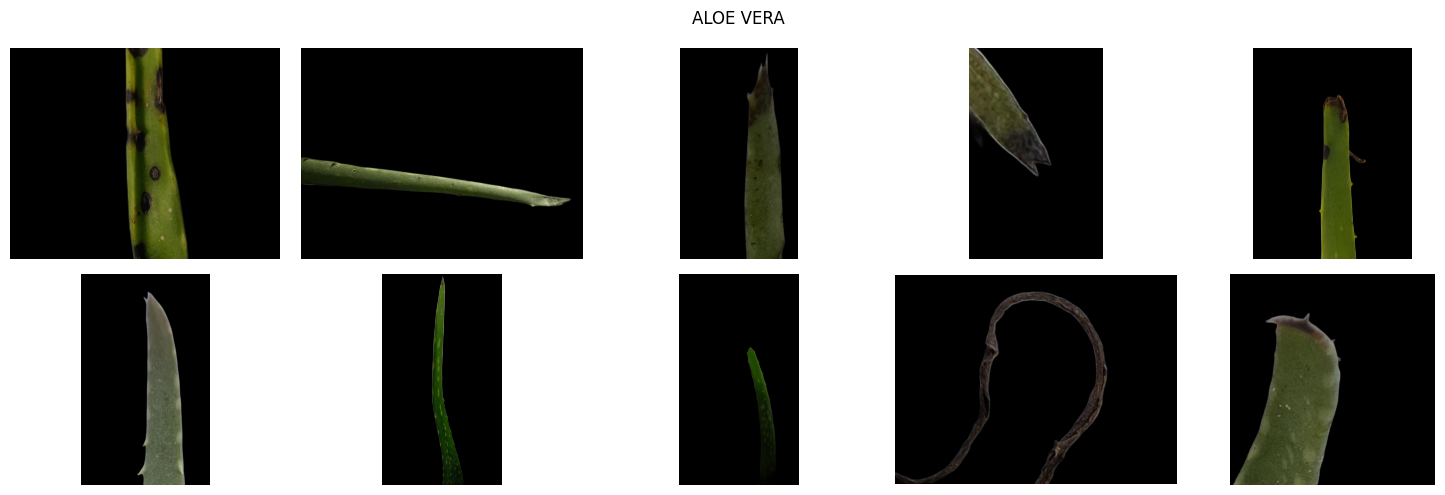


NON-ALOE VERA
Total images: 0


<Figure size 1500x500 with 0 Axes>

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

DATASET = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

folders = {
    "ALOE VERA": os.path.join(DATASET, "train", "Aloe_Vera"),
    "NON-ALOE VERA": os.path.join(DATASET, "train", "Non_Aloe_Vera")
}

for title, folder in folders.items():

    print("\n" + "=" * 40)
    print(title)
    print("=" * 40)

    if not os.path.exists(folder):
        print("Folder not found:", folder)
        continue

    images = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Total images:", len(images))

    plt.figure(figsize=(15, 5))

    for i, path in enumerate(images[:10]):
        img = Image.open(path).convert("RGB")

        plt.subplot(2, 5, i + 1)
        plt.imshow(img)
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
import os
from PIL import Image

DATASET = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

folders = {
    "ALOE VERA": DATASET + "/train/Aloe_Vera",
    "NON-ALOE VERA": DATASET + "/train/Non_Aloe_Vera"
}

for name, folder in folders.items():

    print("\n==========", name, "==========")

    files_list = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for filename in files_list[:10]:
        path = os.path.join(folder, filename)

        try:
            img = Image.open(path)
            print(filename, "| Size:", img.size, "| Format:", img.format)
        except Exception as e:
            print("Error:", filename, e)


========== ALOE VERA ==========
image_0.png | Size: (655, 513) | Format: PNG
image_1.jpeg | Size: (4032, 3024) | Format: JPEG
image_2.jpg | Size: (592, 1060) | Format: JPEG
image_3.jpg | Size: (381, 601) | Format: JPEG
image_4.jpg | Size: (3072, 4080) | Format: JPEG
image_5.jpeg | Size: (929, 1529) | Format: JPEG
image_6.jpg | Size: (2256, 4000) | Format: JPEG
image_7.jpg | Size: (2256, 4000) | Format: JPEG
image_8.png | Size: (371, 274) | Format: PNG
image_9.jpeg | Size: (817, 841) | Format: JPEG

========== NON-ALOE VERA ==========


In [ ]:
import os

print("ZIP file exists:", os.path.exists(zip_path) if 'zip_path' in globals() else "No saved path")

if 'zip_path' in globals():
    print("ZIP location:", zip_path)

ZIP file exists: True
ZIP location: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip


In [ ]:
import zipfile
from collections import Counter
import os

zip_path = "/root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:

    image_files = [
        name for name in z.namelist()
        if name.startswith("raw/color/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    folders = Counter(
        name.split("/")[2]
        for name in image_files
        if len(name.split("/")) > 3
    )

print("Total images:", len(image_files))
print("\nPlant categories:")

for category, count in folders.items():
    print(category, ":", count)

ZIP exists: True
Total images: 54305

Plant categories:
Raspberry___healthy : 371
Potato___Late_blight : 1000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513
Tomato___Early_blight : 1000
Apple___healthy : 1645
Tomato___Tomato_mosaic_virus : 373
Corn_(maize)___Northern_Leaf_Blight : 985
Corn_(maize)___Common_rust_ : 1192
Corn_(maize)___healthy : 1162
Cherry_(including_sour)___healthy : 854
Orange___Haunglongbing_(Citrus_greening) : 5507
Soybean___healthy : 5090
Strawberry___Leaf_scorch : 1109
Tomato___healthy : 1591
Grape___Esca_(Black_Measles) : 1383
Grape___Black_rot : 1180
Cherry_(including_sour)___Powdery_mildew : 1052
Tomato___Target_Spot : 1404
Peach___healthy : 360
Potato___Early_blight : 1000
Pepper,_bell___healthy : 1478
Tomato___Bacterial_spot : 2127
Apple___Apple_scab : 630
Tomato___Septoria_leaf_spot : 1771
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 5357
Squash___Powdery_mildew : 1835
Peach___Bacterial_spot : 2297
Blueberry___healthy : 1502
Tomato___Spider_mites Two-s

In [ ]:
import zipfile
import os
import random
import shutil

zip_path = "/root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip"

DEST = "/content/drive/MyDrive/AloeCare_Verification_Dataset/test/Non_Aloe_Vera"

os.makedirs(DEST, exist_ok=True)

random.seed(42)

with zipfile.ZipFile(zip_path, "r") as z:

    image_files = [
        name for name in z.namelist()
        if name.startswith("raw/color/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected = random.sample(image_files, 500)

    for i, file in enumerate(selected):
        extension = os.path.splitext(file)[1]

        output = os.path.join(
            DEST, f"non_aloe_{i}{extension}"
        )

        with z.open(file) as source:
            with open(output, "wb") as target:
                shutil.copyfileobj(source, target)

print("NON-ALOE DATASET PREPARATION COMPLETED!")
print("Total images:", len(os.listdir(DEST)))
print("Saved location:", DEST)

NON-ALOE DATASET PREPARATION COMPLETED!
Total images: 500
Saved location: /content/drive/MyDrive/AloeCare_Verification_Dataset/test/Non_Aloe_Vera


In [ ]:
import os

TEST_DIR = "/content/drive/MyDrive/AloeCare_Verification_Dataset/test"

for folder in ["Aloe_Vera", "Non_Aloe_Vera"]:
    path = os.path.join(TEST_DIR, folder)

    images = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print(folder, ":", len(images), "images")

Aloe_Vera : 0 images
Non_Aloe_Vera : 500 images


In [ ]:
import os

for path in [
    "/content/drive/MyDrive",
    "/content/gdrive/MyDrive"
]:
    print("\nChecking:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Folders:", os.listdir(path)[:30])


Checking: /content/drive/MyDrive
Exists: True
Folders: ['AloeCare_Models', 'AloeCare_Verification_Dataset']

Checking: /content/gdrive/MyDrive
Exists: True
Folders: ['Classroom', 'database.sql', 'JWT.pdf', 'Research paper(1).pdf', 'Research paper(1).gdoc', 'TT.jpeg', 'Colab Notebooks', 'Untitled document.gdoc', 'Resume.gdoc', 'SILAN MARBANIANG resume.pdf', 'Silan_Marbaniang_Resume.gdoc', 'Silan_Marbaniang_Resume_Styled.gdoc', 'my resume (1).pdf', 'my resume.pdf', 'IMG-20261001-WA0007.jpg', 'Aloe Vera Leaf Disease Detection Paper.pdf', 'Aloe Vera Disease Detection Final Research Report.md', 'YOLO11', 'yolo11_2.gprj', 'Demographic Analysis of Literacy Rates in Rural Meghalaya.docx', 'Aloe Disease Classification - Phase 2 Progress Seminar.gslides', 'DC2025MCA0030-DC2025MCA0024.pdf', 'LIteracy.pdf', 'Aloe_Vera_Project', 'AloeCare_Models', 'AloeCare_Verification_Dataset']


In [ ]:
import os

SOURCE = "/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset"

print("Dataset exists:", os.path.exists(SOURCE))

for root, dirs, files in os.walk(SOURCE):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if images:
        print(root, ":", len(images), "images")

Dataset exists: True
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final/Healthy : 781 images
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final/Aloe Rust : 210 images
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final/Sunburn : 510 images
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final/Leaf Spot : 500 images
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final/Anthracnose : 500 images


In [ ]:
import os

SOURCE = "/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset"

for root, dirs, files in os.walk(SOURCE):
    if dirs:
        print(root)
        print("Subfolders:", dirs)

/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset
Subfolders: ['final']
/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final
Subfolders: ['Healthy', 'Aloe Rust', 'Sunburn', 'Leaf Spot', 'Anthracnose']


In [ ]:
import os
import random
import shutil

SOURCE = "/content/gdrive/MyDrive/YOLO11/New_Aloe_Vera_Dataset/final"

DEST = "/content/drive/MyDrive/AloeCare_Verification_Dataset/test/Aloe_Vera"

os.makedirs(DEST, exist_ok=True)

classes = [
    "Healthy",
    "Aloe Rust",
    "Sunburn",
    "Leaf Spot",
    "Anthracnose"
]

random.seed(42)

count = 0

for category in classes:

    folder = os.path.join(SOURCE, category)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    selected = random.sample(images, min(20, len(images)))

    for i, filename in enumerate(selected):

        source_file = os.path.join(folder, filename)

        extension = os.path.splitext(filename)[1]

        new_name = f"{category.replace(' ', '_')}_{i}{extension}"

        destination_file = os.path.join(DEST, new_name)

        shutil.copy2(source_file, destination_file)

        count += 1

    print(category, ":", len(selected), "images copied")

print("\nTOTAL ALOE VERA IMAGES:", count)

Healthy : 20 images copied
Aloe Rust : 20 images copied
Sunburn : 20 images copied
Leaf Spot : 20 images copied
Anthracnose : 20 images copied

TOTAL ALOE VERA IMAGES: 100


In [ ]:
TEST_DIR = "/content/drive/MyDrive/AloeCare_Verification_Dataset/test"

for folder in ["Aloe_Vera", "Non_Aloe_Vera"]:
    path = os.path.join(TEST_DIR, folder)
    print(folder, ":", len(os.listdir(path)), "images")

Aloe_Vera : 100 images
Non_Aloe_Vera : 500 images


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/AloeCare_Models"

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

In [ ]:
from ultralytics import YOLO

MODEL_PATH = "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"

verify_model = YOLO(MODEL_PATH)

print("MODEL LOADED SUCCESSFULLY!")
print("Task:", verify_model.task)
print("Classes:", verify_model.names)

MODEL LOADED SUCCESSFULLY!
Task: classify
Classes: {0: 'Aloe_Vera', 1: 'Non_Aloe_Vera'}


In [ ]:
import os

locations = [
    "/content/drive/MyDrive",
    "/content/gdrive/MyDrive"
]

print("SEARCHING FOR YOLO11 MODEL...\n")

for location in locations:
    for root, dirs, files in os.walk(location):
        for file in files:
            if file.endswith(".pt"):
                print("MODEL FOUND:", os.path.join(root, file))

SEARCHING FOR YOLO11 MODEL...

MODEL FOUND: /content/gdrive/MyDrive/YOLO11/best.pt
MODEL FOUND: /content/gdrive/MyDrive/YOLO11/runs/aloe_random_oversampling/weights/best.pt
MODEL FOUND: /content/gdrive/MyDrive/YOLO11/runs/aloe_random_oversampling/weights/last.pt
MODEL FOUND: /content/gdrive/MyDrive/YOLO11/runs/aloe_vera_detection/weights/last.pt
MODEL FOUND: /content/gdrive/MyDrive/YOLO11/runs/aloe_vera_detection/weights/best.pt
MODEL FOUND: /content/gdrive/MyDrive/Aloe_Vera_Project/best.pt
MODEL FOUND: /content/gdrive/MyDrive/AloeCare_Models/classify_best.pt
MODEL FOUND: /content/gdrive/MyDrive/AloeCare_Models/detect_best.pt
MODEL FOUND: /content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt


In [ ]:
VERIFICATION_MODEL = "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"

In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

In [ ]:
from ultralytics import YOLO

verify_model = YOLO(VERIFICATION_MODEL)

In [ ]:
CLASSIFY_MODEL = "/content/gdrive/MyDrive/AloeCare_Models/classify_best.pt"

disease_model = YOLO(CLASSIFY_MODEL)

In [ ]:
from ultralytics import YOLO

DATASET_PATH = "/content/gdrive/MyDrive/AloeCare_Verification_Dataset"

# Load pretrained YOLO11 classification model
model = YOLO("yolo11n-cls.pt")

# Train the corrected verification model
results = model.train(
    data=DATASET_PATH,
    epochs=5,
    imgsz=224,
    batch=8,
    patience=3,
    device="cpu",
    workers=2,
    project="/content/runs",
    name="aloe_verification_v2",
    exist_ok=True,
    plots=True
)

print("Verification model training completed!")

In [ ]:
from ultralytics import YOLO

verify_model = YOLO(
    "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"
)

test_images = [
    "/content/aloevera1.jpg",
    "/content/certificate.jpg"
]

for image_path in test_images:
    if os.path.exists(image_path):
        result = verify_model.predict(image_path, imgsz=224, verbose=False)[0]

        aloe_probability = float(result.probs.data[0])
        non_aloe_probability = float(result.probs.data[1])

        print("\nImage:", os.path.basename(image_path))
        print("Aloe vera:", round(aloe_probability * 100, 2), "%")
        print("Non-Aloe:", round(non_aloe_probability * 100, 2), "%")
        print("Prediction:", verify_model.names[result.probs.top1])

In [ ]:
# ============================================================
# ALOECARE - LOAD THREE MODELS
# ============================================================

import os
from ultralytics import YOLO

# MODEL PATHS
VERIFY_PATH = "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"

CLASSIFY_PATH = "/content/gdrive/MyDrive/YOLO11/best.pt"

DETECT_PATH = "/content/gdrive/MyDrive/YOLO11/runs/aloe_vera_detection/weights/best.pt"


# CHECK MODEL FILES
for path in [VERIFY_PATH, CLASSIFY_PATH, DETECT_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Model file not found: {path}")


# LOAD MODELS
verify_model = YOLO(VERIFY_PATH)
classify_model = YOLO(CLASSIFY_PATH)
detect_model = YOLO(DETECT_PATH)


print("ALL THREE MODELS LOADED SUCCESSFULLY!")

print("\nVerification classes:", verify_model.names)
print("Classification classes:", classify_model.names)
print("Detection classes:", detect_model.names)

In [ ]:

# ============================================================
# STEP 2: ALOE VERA IMAGE VERIFICATION
# ============================================================

def verify_aloe_image(image):

    if image is None:
        return False, "Please upload an image."

    try:
        result = verify_model.predict(
            image,
            imgsz=224,
            verbose=False
        )[0]

        aloe_probability = float(result.probs.data[0])
        non_aloe_probability = float(result.probs.data[1])

        # Accept only when Aloe Vera probability is at least 80%
        if aloe_probability >= 0.80:

            return True, (
                f" Aloe vera image accepted!\n"
                f"Aloe vera confidence: {aloe_probability * 100:.2f}%"
            )

        else:

            return False, (
                "Invalid Image!\n"
                "Please upload an Aloe vera leaf image only.\n"
                f"Non-Aloe confidence: {non_aloe_probability * 100:.2f}%"
            )

    except Exception as e:
        return False, f"Unable to verify image: {str(e)}"


print("Aloe vera verification function created successfully!")


In [ ]:

from PIL import Image

# Test Aloe vera image
image1 = Image.open("/content/aloevera1.jpg").convert("RGB")

accepted, message = verify_aloe_image(image1)

print("ALOE VERA TEST:")
print(message)


# Test certificate image
image2 = Image.open("/content/certificate.jpg").convert("RGB")

accepted, message = verify_aloe_image(image2)

print("\nCERTIFICATE TEST:")
print(message)


In [ ]:

# ============================================================
# STEP 3: CLASSIFICATION AND DETECTION WITH VERIFICATION
# ============================================================

import numpy as np
from PIL import Image


# ------------------------------------------------------------
# CLASSIFICATION FUNCTION
# ------------------------------------------------------------

def classify_leaf(image):

    if image is None:
        return "Please upload an image."

    # FIRST: VERIFY ALOE VERA
    accepted, message = verify_aloe_image(image)

    if not accepted:
        return message

    # SECOND: RUN CLASSIFICATION MODEL
    result = classify_model.predict(
        image,
        imgsz=224,
        verbose=False
    )[0]

    probabilities = result.probs.data.cpu().numpy()

    predicted_class = classify_model.names[result.probs.top1]
    confidence = float(probabilities[result.probs.top1]) * 100

    report = f"""
## AloeCare Classification Result

**Verification:** Aloe vera accepted

**Predicted Condition:** {predicted_class}

**Confidence:** {confidence:.2f}%

### Class Probabilities
"""

    for index, probability in enumerate(probabilities):
        class_name = classify_model.names[index]
        report += f"\n- {class_name}: {probability * 100:.2f}%"

    return report


# ------------------------------------------------------------
# DETECTION FUNCTION
# ------------------------------------------------------------

def detect_leaf(image):

    if image is None:
        return None, "Please upload an image."

    # FIRST: VERIFY ALOE VERA
    accepted, message = verify_aloe_image(image)

    if not accepted:
        return None, message

    # SECOND: RUN DETECTION MODEL
    result = detect_model.predict(
        image,
        imgsz=960,
        conf=0.25,
        verbose=False
    )[0]

    # CHECK DETECTED DISEASES
    if result.boxes is None or len(result.boxes) == 0:

        return (
            image,
            "Aloe vera image accepted.\n"
            "No disease detected. The leaf may be healthy."
        )

    # GET ANNOTATED IMAGE
    annotated_image = Image.fromarray(
        result.plot()[..., ::-1]
    )

    detected_diseases = []

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0]) * 100

        disease_name = detect_model.names[class_id]

        detected_diseases.append(
            f"- {disease_name}: {confidence:.2f}%"
        )

    report = (
        "## AloeCare Disease Detection Result\n\n"
        "**Verification:** Aloe vera accepted\n\n"
        "**Detected Diseases:**\n"
        + "\n".join(detected_diseases)
    )

    return annotated_image, report


print("Classification and detection functions created successfully!")


In [ ]:
# ============================================================
#                       ALOECARE WEBSITE
#          Aloe Vera Verification, Classification & Detection
# ============================================================

import os
import re
import sqlite3
import hashlib
import secrets
import requests
import gradio as gr
import numpy as np

from PIL import Image
from ultralytics import YOLO
from google.colab import drive


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/gdrive')


# ============================================================
# 2. MODEL PATHS
# ============================================================

VERIFY_PATH = (
    "/content/gdrive/MyDrive/AloeCare_Models/"
    "aloe_verification_best.pt"
)

CLASSIFY_PATH = (
    "/content/gdrive/MyDrive/YOLO11/best.pt"
)

DETECT_PATH = (
    "/content/gdrive/MyDrive/YOLO11/runs/"
    "aloe_vera_detection/weights/best.pt"
)

DB_PATH = (
    "/content/gdrive/MyDrive/YOLO11/aloecare_users.db"
)


# ============================================================
# 3. CHECK MODEL FILES
# ============================================================

model_paths = [
    VERIFY_PATH,
    CLASSIFY_PATH,
    DETECT_PATH
]

for path in model_paths:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Model file not found: {path}"
        )

print("All model files found!")


# ============================================================
# 4. LOAD ALL THREE YOLO MODELS
# ============================================================

print("Loading AloeCare models...")

verification_model = YOLO(VERIFY_PATH)
classification_model = YOLO(CLASSIFY_PATH)
detection_model = YOLO(DETECT_PATH)

print("\nALL THREE MODELS LOADED SUCCESSFULLY!")

print("\nVerification classes:")
print(verification_model.names)

print("\nClassification classes:")
print(classification_model.names)

print("\nDetection classes:")
print(detection_model.names)


# ============================================================
# 5. DATABASE SETUP
# ============================================================

def create_database():

    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            full_name TEXT NOT NULL,
            email TEXT UNIQUE NOT NULL,
            password_hash TEXT NOT NULL,
            salt TEXT NOT NULL
        )
    """)

    conn.commit()
    conn.close()


create_database()

print("\nDatabase ready!")


# ============================================================
# 6. PASSWORD HASHING
# ============================================================

def hash_password(password, salt):

    password_hash = hashlib.pbkdf2_hmac(
        "sha256",
        password.encode(),
        salt.encode(),
        200000
    )

    return password_hash.hex()


# ============================================================
# 7. USER REGISTRATION
# ============================================================

def register_user(full_name, email, password, confirm_password):

    full_name = (full_name or "").strip()
    email = (email or "").strip().lower()

    if not full_name or not email or not password:
        return "Please fill in all the fields."

    if not re.match(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", email):
        return "Please enter a valid email address."

    if len(password) < 6:
        return "Password must contain at least 6 characters."

    if password != confirm_password:
        return "Passwords do not match."

    salt = secrets.token_hex(16)
    password_hash = hash_password(password, salt)

    try:

        conn = sqlite3.connect(DB_PATH)
        cursor = conn.cursor()

        cursor.execute("""
            INSERT INTO users
            (full_name, email, password_hash, salt)
            VALUES (?, ?, ?, ?)
        """, (
            full_name,
            email,
            password_hash,
            salt
        ))

        conn.commit()
        conn.close()

        return "Account created successfully! Please login."

    except sqlite3.IntegrityError:

        return "This email is already registered."

    except Exception as e:

        return f"Registration error: {str(e)}"


# ============================================================
# 8. USER LOGIN
# ============================================================

def login_user(email, password):

    email = (email or "").strip().lower()

    if not email or not password:
        return False, "Please enter your email and password."

    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()

    cursor.execute("""
        SELECT full_name, password_hash, salt
        FROM users
        WHERE email = ?
    """, (email,))

    user = cursor.fetchone()

    conn.close()

    if user is None:
        return False, "Account not found. Please register first."

    full_name, saved_hash, salt = user

    entered_hash = hash_password(password, salt)

    if secrets.compare_digest(entered_hash, saved_hash):

        return True, f"Welcome, {full_name}!"

    return False, "Incorrect email or password."


# ============================================================
# 9. ALOE VERA IMAGE VERIFICATION
# ============================================================

def verify_aloe_image(image):

    if image is None:
        return False, "Please upload an image first."

    try:

        results = verification_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )

        result = results[0]

        if result.probs is None:
            return False, "Unable to verify this image."

        probabilities = result.probs.data.cpu().numpy()

        predicted_index = int(np.argmax(probabilities))

        class_names = verification_model.names

        predicted_class = class_names[predicted_index]

        confidence = float(probabilities[predicted_index])

        if isinstance(predicted_class, str):
            predicted_class = predicted_class.replace(" ", "_")

        if predicted_class == "Aloe_Vera" and confidence >= 0.80:

            return True, (
                f"Aloe vera image verified successfully "
                f"({confidence * 100:.2f}%)."
            )

        return False, (
            "Image rejected! Please upload an Aloe vera leaf image."
        )

    except Exception as e:

        return False, f"Verification error: {str(e)}"


# ============================================================
# 10. DISEASE CLASSIFICATION
# ============================================================

def classify_leaf(image):

    if image is None:
        return "Please upload an image first."

    is_aloe, message = verify_aloe_image(image)

    if not is_aloe:
        return message

    try:

        results = classification_model.predict(
            source=image,
            imgsz=224,
            verbose=False
        )

        result = results[0]

        probabilities = result.probs.data.cpu().numpy()

        class_names = classification_model.names

        top_index = int(np.argmax(probabilities))

        disease_name = class_names[top_index]

        confidence = float(probabilities[top_index]) * 100

        output = (
            "ALOECARE CLASSIFICATION RESULT\n"
            "================================\n\n"
            f"Verification: Aloe vera accepted\n"
            f"Disease: {disease_name}\n"
            f"Confidence: {confidence:.2f}%\n\n"
        )

        top_indices = np.argsort(probabilities)[::-1][:3]

        output += "TOP 3 PREDICTIONS\n"
        output += "----------------------------\n"

        for index in top_indices:

            name = class_names[int(index)]

            score = float(probabilities[index]) * 100

            output += f"{name}: {score:.2f}%\n"

        return output

    except Exception as e:

        return f"Classification error: {str(e)}"


# ============================================================
# 11. DISEASE DETECTION
# ============================================================

def detect_leaf(image):

    if image is None:
        return None, "Please upload an image first."

    is_aloe, message = verify_aloe_image(image)

    if not is_aloe:
        return None, message

    try:

        results = detection_model.predict(
            source=image,
            imgsz=960,
            conf=0.25,
            verbose=False
        )

        result = results[0]

        annotated_image = result.plot()

        annotated_image = Image.fromarray(
            annotated_image[:, :, ::-1]
        )

        if result.boxes is None or len(result.boxes) == 0:

            return (
                annotated_image,
                "No disease detected. The leaf may be healthy."
            )

        class_names = detection_model.names

        output = (
            "ALOECARE DISEASE DETECTION RESULT\n"
            "================================\n\n"
        )

        detected_count = 0

        for box in result.boxes:

            class_id = int(box.cls[0])

            confidence = float(box.conf[0]) * 100

            disease_name = class_names[class_id]

            detected_count += 1

            output += (
                f"{detected_count}. {disease_name} "
                f"- {confidence:.2f}% confidence\n"
            )

        output += (
            f"\nTotal detections: {detected_count}"
        )

        return annotated_image, output

    except Exception as e:

        return None, f"Detection error: {str(e)}"


# ============================================================
# 12. DOWNLOAD A NATURAL ALOE VERA BANNER IMAGE
# ============================================================

ALOE_IMAGE_PATH = "/content/aloe_vera_banner.jpg"

if not os.path.exists(ALOE_IMAGE_PATH):

    try:

        image_url = (
            "https://commons.wikimedia.org/wiki/Special:"
            "FilePath/Aloe_Vera_plant.jpg"
        )

        response = requests.get(
            image_url,
            timeout=20,
            headers={"User-Agent": "AloeCare/1.0"}
        )

        response.raise_for_status()

        with open(ALOE_IMAGE_PATH, "wb") as file:
            file.write(response.content)

        # Check that the downloaded file is a valid image.
        with Image.open(ALOE_IMAGE_PATH) as test_image:
            test_image.verify()

        print("Aloe vera banner image downloaded.")

    except Exception as e:

        print("Banner image could not be downloaded:", e)
        ALOE_IMAGE_PATH = None


# ============================================================
# 13. WEBSITE DESIGN
# ============================================================

custom_css = """

/* Main page background */

.gradio-container {
    background: #f8fbf6 !important;
    color: #111111 !important;
}

/* All text black */

.gradio-container,
.gradio-container p,
.gradio-container label,
.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container span,
.gradio-container div {
    color: #111111;
}

/* Small soft green buttons */

button {
    background: #dcebd8 !important;
    color: #111111 !important;
    border: 1px solid #b8d2b1 !important;
    border-radius: 10px !important;
}

/* Button hover */

button:hover {
    background: #cfe3c8 !important;
}

/* Input boxes */

input,
textarea {
    background: #ffffff !important;
    color: #111111 !important;
    border: 1px solid #cbd8c7 !important;
    border-radius: 8px !important;
}

/* Tabs */

.tab-nav button {
    background: #eaf2e7 !important;
    color: #111111 !important;
}

/* Soft green panels */

.soft-green {
    background: #f0f6ed !important;
    border: 1px solid #d8e6d2 !important;
    border-radius: 12px !important;
    padding: 15px !important;
}

/* Welcome title */

.welcome-title {
    text-align: center;
    font-size: 35px;
    font-weight: bold;
    color: #111111 !important;
    margin-top: 10px;
}

/* Welcome text */

.welcome-text {
    text-align: center;
    font-size: 16px;
    color: #111111 !important;
    margin-bottom: 20px;
}

/* Image banner */

.banner-image img {
    max-height: 210px !important;
    object-fit: cover !important;
    border-radius: 14px !important;
}

"""


# ============================================================
# 14. GRADIO WEBSITE
# ============================================================

with gr.Blocks(
    title="AloeCare",
    css=custom_css,
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="green",
        neutral_hue="slate"
    )
) as demo:


    # ========================================================
    # SESSION STATE
    # ========================================================

    logged_in = gr.State(False)


    # ========================================================
    # WELCOME PAGE
    # ========================================================

    with gr.Column(visible=True) as welcome_page:

        gr.HTML("""
            <div style="text-align:center; padding:10px;">
                <h1 style="
                    color:#111111;
                    font-size:36px;
                    margin-bottom:5px;
                ">
                    Welcome to AloeCare
                </h1>

                <p style="
                    color:#111111;
                    font-size:16px;
                ">
                    Welcome! Please register or login to continue.
                </p>
            </div>
        """)

        if ALOE_IMAGE_PATH and os.path.exists(ALOE_IMAGE_PATH):

            gr.Image(
                value=ALOE_IMAGE_PATH,
                label=None,
                show_label=False,
                interactive=False,
                height=210,
                elem_classes=["banner-image"]
            )

        with gr.Row():

            with gr.Column(
                scale=1,
                elem_classes=["soft-green"]
            ):

                gr.Markdown(
                    "### Register",
                    elem_id="register-heading"
                )

                register_button = gr.Button(
                    "Create Account",
                    variant="secondary"
                )

            with gr.Column(
                scale=1,
                elem_classes=["soft-green"]
            ):

                gr.Markdown(
                    "### Login",
                    elem_id="login-heading"
                )

                login_button = gr.Button(
                    "Login",
                    variant="secondary"
                )


    # ========================================================
    # REGISTRATION PAGE
    # ========================================================

    with gr.Column(visible=False) as registration_page:

        gr.Markdown("## Create Your AloeCare Account")

        reg_name = gr.Textbox(
            label="Full Name",
            placeholder="Enter your full name"
        )

        reg_email = gr.Textbox(
            label="Email Address",
            placeholder="Enter your email"
        )

        reg_password = gr.Textbox(
            label="Password",
            placeholder="Enter your password",
            type="password"
        )

        show_reg_password = gr.Checkbox(
            label="Show Password"
        )

        reg_confirm_password = gr.Textbox(
            label="Confirm Password",
            placeholder="Re-enter your password",
            type="password"
        )

        show_confirm_password = gr.Checkbox(
            label="Show Confirm Password"
        )

        create_account_button = gr.Button(
            "Create Account"
        )

        reg_status = gr.Textbox(
            label="Registration Status",
            interactive=False
        )

        back_register = gr.Button(
            "Back to Welcome"
        )


    # ========================================================
    # LOGIN PAGE
    # ========================================================

    with gr.Column(visible=False) as login_page:

        gr.Markdown("## Login to AloeCare")

        login_email = gr.Textbox(
            label="Email Address",
            placeholder="Enter your email"
        )

        login_password = gr.Textbox(
            label="Password",
            placeholder="Enter your password",
            type="password"
        )

        show_login_password = gr.Checkbox(
            label="Show Password"
        )

        login_submit_button = gr.Button(
            "Login"
        )

        login_status = gr.Textbox(
            label="Login Status",
            interactive=False
        )

        back_login = gr.Button(
            "Back to Welcome"
        )


    # ========================================================
    # DASHBOARD PAGE
    # ========================================================

    with gr.Column(visible=False) as dashboard_page:

        gr.Markdown("# AloeCare Dashboard")

        gr.Markdown(
            "Upload an Aloe vera leaf image to use the available tools."
        )

        logout_button = gr.Button(
            "Logout"
        )

        with gr.Tabs():

            # ------------------------------------------------
            # CLASSIFICATION TAB
            # ------------------------------------------------

            with gr.Tab("Classification"):

                gr.Markdown("### Aloe Vera Disease Classification")

                classify_image = gr.Image(
                    label="Upload Aloe Vera Leaf",
                    type="pil"
                )

                classify_button = gr.Button(
                    "Classify Image"
                )

                classify_output = gr.Textbox(
                    label="Classification Result",
                    lines=10,
                    interactive=False
                )

                classify_button.click(
                    fn=classify_leaf,
                    inputs=classify_image,
                    outputs=classify_output
                )


            # ------------------------------------------------
            # DETECTION TAB
            # ------------------------------------------------

            with gr.Tab("Detection"):

                gr.Markdown("### Aloe Vera Disease Detection")

                detect_image = gr.Image(
                    label="Upload Aloe Vera Leaf",
                    type="pil"
                )

                detect_button = gr.Button(
                    "Detect Disease"
                )

                detect_output_image = gr.Image(
                    label="Detection Result",
                    interactive=False
                )

                detect_output_text = gr.Textbox(
                    label="Detection Details",
                    lines=8,
                    interactive=False
                )

                detect_button.click(
                    fn=detect_leaf,
                    inputs=detect_image,
                    outputs=[
                        detect_output_image,
                        detect_output_text
                    ]
                )


    # ========================================================
    # 15. PAGE NAVIGATION
    # ========================================================

    def open_register():

        return (
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False)
        )


    def open_login():

        return (
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )


    def back_to_welcome():

        return (
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=False)
        )


    def successful_login(email, password):

        success, message = login_user(email, password)

        if success:

            return (
                message,
                True,
                gr.update(visible=False),
                gr.update(visible=False),
                gr.update(visible=False),
                gr.update(visible=True)
            )

        return (
            message,
            False,
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False)
        )


    def logout_user():

        return (
            False,
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=False)
        )


    # ========================================================
    # 16. REGISTER BUTTON EVENTS
    # ========================================================

    register_button.click(
        fn=open_register,
        outputs=[
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )


    # ========================================================
    # 17. LOGIN BUTTON EVENTS
    # ========================================================

    login_button.click(
        fn=open_login,
        outputs=[
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )


    # ========================================================
    # 18. BACK BUTTON EVENTS
    # ========================================================

    back_register.click(
        fn=back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )

    back_login.click(
        fn=back_to_welcome,
        outputs=[
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )


    # ========================================================
    # 19. REGISTRATION EVENT
    # ========================================================

    create_account_button.click(
        fn=register_user,
        inputs=[
            reg_name,
            reg_email,
            reg_password,
            reg_confirm_password
        ],
        outputs=reg_status
    )


    # ========================================================
    # 20. LOGIN EVENT
    # ========================================================

    login_submit_button.click(
        fn=successful_login,
        inputs=[
            login_email,
            login_password
        ],
        outputs=[
            login_status,
            logged_in,
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )


    # ========================================================
    # 21. LOGOUT EVENT
    # ========================================================

    logout_button.click(
        fn=logout_user,
        outputs=[
            logged_in,
            welcome_page,
            registration_page,
            login_page,
            dashboard_page
        ]
    )


    # ========================================================
    # 22. SHOW / HIDE PASSWORD EVENTS
    # ========================================================

    show_reg_password.change(
        fn=lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=show_reg_password,
        outputs=reg_password
    )

    show_confirm_password.change(
        fn=lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=show_confirm_password,
        outputs=reg_confirm_password
    )

    show_login_password.change(
        fn=lambda show: gr.update(
            type="text" if show else "password"
        ),
        inputs=show_login_password,
        outputs=login_password
    )


# ============================================================
# 23. LAUNCH WEBSITE
# ============================================================

print("\nStarting AloeCare website...")

demo.launch(
    share=True,
    debug=True
)

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
All model files found!
Loading AloeCare models...

ALL THREE MODELS LOADED SUCCESSFULLY!

Verification classes:
{0: 'Aloe_Vera', 1: 'Non_Aloe_Vera'}

Classification classes:
{0: 'Aloe Rust', 1: 'Anthracnose', 2: 'Healthy', 3: 'Leaf Spot', 4: 'Sunburn'}

Detection classes:
{0: 'Aloe Rust', 1: 'Anthracnose', 2: 'Leaf Spot', 3: 'Sunburn'}

Database ready!
Aloe vera banner image downloaded.


/tmp/ipykernel_6924/2893121457.py:552: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(



Starting AloeCare website...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://432b9aa1c0760c16c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ==========================================
# ALOECARE - STARTUP CELL
# ==========================================

!pip install -q ultralytics

import os
from google.colab import drive
from ultralytics import YOLO

# Mount Google Drive
drive.mount('/content/drive')

# Mount the second Drive location if needed
if not os.path.exists('/content/gdrive/MyDrive'):
    drive.mount('/content/gdrive')

print("Google Drive connected!")

# Model locations
VERIFY_PATH = "/content/gdrive/MyDrive/AloeCare_Models/aloe_verification_best.pt"
CLASSIFY_PATH = "/content/gdrive/MyDrive/AloeCare_Models/classify_best.pt"

# Verification dataset
TEST_DIR = "/content/drive/MyDrive/AloeCare_Verification_Dataset/test"

# Check files
print("Verification model exists:", os.path.exists(VERIFY_PATH))
print("Classification model exists:", os.path.exists(CLASSIFY_PATH))
print("Verification dataset exists:", os.path.exists(TEST_DIR))

# Load models
verify_model = YOLO(VERIFY_PATH)
disease_model = YOLO(CLASSIFY_PATH)

print("\nBOTH MODELS LOADED SUCCESSFULLY!")
print("Verification classes:", verify_model.names)
print("Disease classes:", disease_model.names)

print("\nAloeCare is ready!")
